In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_09/GT.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_09/Patient_09.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_05/GT.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_05/Patient_05.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_37/Patient_37.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_37/GT.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_38/GT.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_38/Patient_38.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_39/GT.nii
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor/Patient_39/Patient_39.nii
/kaggle/in

In [2]:
# ==========================================================
# Cell 1: Environment Verification
# ==========================================================

import torch
import torchvision
import numpy as np
import cv2
import SimpleITK as sitk
import matplotlib

print("="*60)
print("APFormer Research Reproduction")
print("="*60)

print(f"PyTorch      : {torch.__version__}")
print(f"Torchvision  : {torchvision.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"OpenCV       : {cv2.__version__}")
print(f"SimpleITK    : {sitk.Version()}")
print(f"Matplotlib   : {matplotlib.__version__}")

print("\nEnvironment Ready ✅")

APFormer Research Reproduction
PyTorch      : 2.10.0+cu128
Torchvision  : 0.25.0+cu128
NumPy        : 2.0.2
OpenCV       : 4.13.0
SimpleITK    : SimpleITK Version: 2.5.5 (ITK 5.4)
Compiled: May 12 2026 17:19:38

Matplotlib   : 3.10.0

Environment Ready ✅


In [3]:
# ==========================================================
# Cell 2: Import Libraries
# ==========================================================

# Standard Libraries
import os
import gc
import random
import time

# Numerical Computing
import numpy as np

# Medical Imaging
import SimpleITK as sitk

# Image Processing
import cv2

# Visualization
import matplotlib.pyplot as plt

# Progress Bar
from tqdm import tqdm

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
# ==========================================================
# Cell 3: Configuration
# ==========================================================

class CFG:

    # Dataset
    DATASET_PATH = "/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor"
    # Image
    IMAGE_SIZE = 224

    # SegTHOR Classes
    NUM_CLASSES = 5

    # Training
    BATCH_SIZE = 8
    EPOCHS = 220

    # Optimizer
    LR = 0.01
    WEIGHT_DECAY = 1e-4

    # Seed
    SEED = 42

cfg = CFG()

print("="*60)
print("Configuration Loaded")
print("="*60)

print("Dataset :", cfg.DATASET_PATH)
print("Image Size :", cfg.IMAGE_SIZE)
print("Classes :", cfg.NUM_CLASSES)
print("Epochs :", cfg.EPOCHS)

Configuration Loaded
Dataset : /kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor
Image Size : 224
Classes : 5
Epochs : 220


In [5]:
# ==========================================================
# Cell 4: Random Seed & Device
# ==========================================================

def seed_everything(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(cfg.SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("="*60)
print("Device :", device)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

print("="*60)

Device : cuda
GPU : Tesla T4


In [6]:
# ==========================================================
# Cell 5: Verify Dataset
# ==========================================================

import os

print("=" * 60)
print("DATASET VERIFICATION")
print("=" * 60)

dataset_path = cfg.DATASET_PATH

print(f"Dataset Path:\n{dataset_path}")

if os.path.exists(dataset_path):
    print("\n✅ Dataset found!")
else:
    print("\n❌ Dataset NOT found!")

print("\nContents:")

for item in sorted(os.listdir(dataset_path))[:10]:
    print(item)

print("\nTotal Patients:", len(os.listdir(dataset_path)))

DATASET VERIFICATION
Dataset Path:
/kaggle/input/datasets/zrohit2408/segthor-preprocessed-224/processed_segthor

✅ Dataset found!

Contents:
Patient_01
Patient_02
Patient_03
Patient_04
Patient_05
Patient_06
Patient_07
Patient_08
Patient_09
Patient_10

Total Patients: 40


In [7]:
# ==========================================================
# Cell 6: Create Patient List
# ==========================================================

import os

# Get all patient folders
patient_list = sorted([
    patient for patient in os.listdir(cfg.DATASET_PATH)
    if os.path.isdir(os.path.join(cfg.DATASET_PATH, patient))
])

print("=" * 60)
print("PATIENT LIST")
print("=" * 60)

print(f"Total Patients : {len(patient_list)}")

print("\nFirst 5 Patients:")
for patient in patient_list[:5]:
    print(patient)

print("\nLast 5 Patients:")
for patient in patient_list[-5:]:
    print(patient)

PATIENT LIST
Total Patients : 40

First 5 Patients:
Patient_01
Patient_02
Patient_03
Patient_04
Patient_05

Last 5 Patients:
Patient_36
Patient_37
Patient_38
Patient_39
Patient_40


In [8]:
# ==========================================================
# Cell 7: Train / Validation Split
# ==========================================================

from sklearn.model_selection import train_test_split

train_patients, val_patients = train_test_split(
    patient_list,
    test_size=0.20,
    random_state=cfg.SEED,
    shuffle=True
)

# Sort for readability
train_patients = sorted(train_patients)
val_patients = sorted(val_patients)

print("=" * 60)
print("TRAIN / VALIDATION SPLIT")
print("=" * 60)

print(f"Training Patients   : {len(train_patients)}")
print(f"Validation Patients : {len(val_patients)}")

print("\nTraining Patients:")
print(train_patients)

print("\nValidation Patients:")
print(val_patients)

TRAIN / VALIDATION SPLIT
Training Patients   : 32
Validation Patients : 8

Training Patients:
['Patient_01', 'Patient_02', 'Patient_03', 'Patient_04', 'Patient_06', 'Patient_07', 'Patient_08', 'Patient_09', 'Patient_10', 'Patient_11', 'Patient_12', 'Patient_14', 'Patient_15', 'Patient_18', 'Patient_19', 'Patient_21', 'Patient_22', 'Patient_23', 'Patient_24', 'Patient_25', 'Patient_26', 'Patient_29', 'Patient_30', 'Patient_31', 'Patient_32', 'Patient_33', 'Patient_34', 'Patient_35', 'Patient_36', 'Patient_37', 'Patient_39', 'Patient_40']

Validation Patients:
['Patient_05', 'Patient_13', 'Patient_16', 'Patient_17', 'Patient_20', 'Patient_27', 'Patient_28', 'Patient_38']


In [9]:
# ==========================================================
# Cell 8: SegTHOR Dataset Class
# ==========================================================

class SegTHORDataset(Dataset):
    """
    SegTHOR Dataset Loader

    Returns:
        image : Tensor [1, D, H, W]
        mask  : Tensor [D, H, W]
    """

    def __init__(self, dataset_path, patient_list):

        self.dataset_path = dataset_path
        self.patient_list = patient_list

    def __len__(self):
        return len(self.patient_list)

    def __getitem__(self, idx):

        patient = self.patient_list[idx]

        patient_folder = os.path.join(self.dataset_path, patient)

        image_path = os.path.join(patient_folder, f"{patient}.nii.gz")
        mask_path = os.path.join(patient_folder, "GT.nii.gz")

        # Read image
        image = sitk.ReadImage(image_path)
        image = sitk.GetArrayFromImage(image).astype(np.float32)

        # Read mask
        mask = sitk.ReadImage(mask_path)
        mask = sitk.GetArrayFromImage(mask).astype(np.uint8)

        # Convert to Tensor
        image = torch.from_numpy(image)
        mask = torch.from_numpy(mask)

        # Add channel dimension
        # Image: (D,H,W) -> (1,D,H,W)
        image = image.unsqueeze(0)

        return image, mask

In [10]:
# ==========================================================
# Cell 9: Verify Dataset Class
# ==========================================================

train_dataset = SegTHORDataset(
    cfg.DATASET_PATH,
    train_patients
)

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print(f"Training Samples : {len(train_dataset)}")

image, mask = train_dataset[0]

print("\nImage Shape :", image.shape)
print("Mask Shape  :", mask.shape)

print("\nImage dtype :", image.dtype)
print("Mask dtype  :", mask.dtype)

print("\nImage Range")
print(f"Min : {image.min():.4f}")
print(f"Max : {image.max():.4f}")

print("\nMask Labels")
print(torch.unique(mask))

DATASET INFORMATION
Training Samples : 32

Image Shape : torch.Size([1, 229, 224, 224])
Mask Shape  : torch.Size([229, 224, 224])

Image dtype : torch.float32
Mask dtype  : torch.uint8

Image Range
Min : 0.0000
Max : 1.0000

Mask Labels
tensor([0, 1, 2, 3, 4], dtype=torch.uint8)


In [11]:
# ==========================================================
# Cell 10: Dataset Slice Statistics
# ==========================================================

import pandas as pd
import SimpleITK as sitk
import os
import numpy as np

records = []

for patient in patient_list:
    
    patient_folder = os.path.join(cfg.DATASET_PATH, patient)
    image_path = os.path.join(patient_folder, f"{patient}.nii.gz")
    
    image = sitk.ReadImage(image_path)
    
    # SimpleITK size format: (Width, Height, Depth)
    width, height, depth = image.GetSize()
    spacing = image.GetSpacing()
    
    split = "Train" if patient in train_patients else "Validation"
    
    records.append({
        "Patient": patient,
        "Split": split,
        "Depth_Slices": depth,
        "Height": height,
        "Width": width,
        "Spacing_X": spacing[0],
        "Spacing_Y": spacing[1],
        "Spacing_Z": spacing[2],
    })

df_info = pd.DataFrame(records)

print("=" * 60)
print("DATASET SLICE STATISTICS")
print("=" * 60)

print(f"Total Patients        : {len(df_info)}")
print(f"Training Patients     : {len(train_patients)}")
print(f"Validation Patients   : {len(val_patients)}")

print("\nTotal Slices")
print("-" * 60)
print(f"Training Slices       : {df_info[df_info['Split']=='Train']['Depth_Slices'].sum()}")
print(f"Validation Slices     : {df_info[df_info['Split']=='Validation']['Depth_Slices'].sum()}")
print(f"All Slices            : {df_info['Depth_Slices'].sum()}")

print("\nSlice Count Per CT Volume")
print("-" * 60)
print(f"Minimum Slices        : {df_info['Depth_Slices'].min()}")
print(f"Maximum Slices        : {df_info['Depth_Slices'].max()}")
print(f"Mean Slices           : {df_info['Depth_Slices'].mean():.2f}")
print(f"Median Slices         : {df_info['Depth_Slices'].median():.2f}")

print("\nImage Size Check")
print("-" * 60)
print("Unique Heights:", sorted(df_info["Height"].unique()))
print("Unique Widths :", sorted(df_info["Width"].unique()))

print("\nValidation Patients")
print("-" * 60)
print(val_patients)

print("\nPatient-wise Slice Information")
display(df_info)

DATASET SLICE STATISTICS
Total Patients        : 40
Training Patients     : 32
Validation Patients   : 8

Total Slices
------------------------------------------------------------
Training Slices       : 5819
Validation Slices     : 1601
All Slices            : 7420

Slice Count Per CT Volume
------------------------------------------------------------
Minimum Slices        : 147
Maximum Slices        : 284
Mean Slices           : 185.50
Median Slices         : 177.50

Image Size Check
------------------------------------------------------------
Unique Heights: [np.int64(224)]
Unique Widths : [np.int64(224)]

Validation Patients
------------------------------------------------------------
['Patient_05', 'Patient_13', 'Patient_16', 'Patient_17', 'Patient_20', 'Patient_27', 'Patient_28', 'Patient_38']

Patient-wise Slice Information


,Patient,Split,Depth_Slices,Height,Width,Spacing_X,Spacing_Y,Spacing_Z
0,Patient_01,Train,229,224,224,0.976562,0.976562,2.0
1,Patient_02,Train,246,224,224,0.976562,0.976562,2.5
2,Patient_03,Train,147,224,224,0.976562,0.976562,2.5
3,Patient_04,Train,158,224,224,0.976562,0.976562,2.5
4,Patient_05,Validation,284,224,224,0.976562,0.976562,2.0
5,Patient_06,Train,199,224,224,0.976562,0.976562,2.5
6,Patient_07,Train,179,224,224,0.976562,0.976562,2.0
7,Patient_08,Train,171,224,224,0.976562,0.976562,2.5
8,Patient_09,Train,154,224,224,0.976562,0.976562,2.5
9,Patient_10,Train,163,224,224,0.976562,0.976562,2.0


In [12]:
# ==========================================================
# Cell 11: Data Pipeline Settings
# ==========================================================

# We are training 2D slice-wise models
cfg.TRAINING_MODE = "2D_slice_wise"

# DataLoader settings
cfg.NUM_WORKERS = 0          # safer with caching on Kaggle
cfg.PIN_MEMORY = True if torch.cuda.is_available() else False

# Cache preprocessed volumes in RAM for faster training
# Safe because images are already resized to 224x224
cfg.USE_CACHE = True

# Augmentation settings based on APFormer paper
cfg.FLIP_PROB = 0.5
cfg.ROTATE_PROB = 0.5
cfg.MAX_ROTATION_ANGLE = 15

cfg.CONTRAST_PROB = 0.3
cfg.GAMMA_PROB = 0.3

print("=" * 60)
print("DATA PIPELINE SETTINGS")
print("=" * 60)
print("Training Mode :", cfg.TRAINING_MODE)
print("Use Cache     :", cfg.USE_CACHE)
print("Num Workers   :", cfg.NUM_WORKERS)
print("Pin Memory    :", cfg.PIN_MEMORY)

DATA PIPELINE SETTINGS
Training Mode : 2D_slice_wise
Use Cache     : True
Num Workers   : 0
Pin Memory    : True


In [13]:
# ==========================================================
# Cell 12: Data Augmentation
# ==========================================================

class SegTHORAugmentation:
    """
    Training-time augmentation for SegTHOR.

    Implements augmentations mentioned in the APFormer paper:
    - Random flipping
    - Random rotation
    - Contrast transformation
    - Gamma transformation

    Image shape: (H, W)
    Mask shape : (H, W)
    """

    def __init__(
        self,
        flip_prob=0.5,
        rotate_prob=0.5,
        max_angle=15,
        contrast_prob=0.3,
        gamma_prob=0.3
    ):
        self.flip_prob = flip_prob
        self.rotate_prob = rotate_prob
        self.max_angle = max_angle
        self.contrast_prob = contrast_prob
        self.gamma_prob = gamma_prob

    def __call__(self, image, mask):

        image = image.astype(np.float32)
        mask = mask.astype(np.uint8)

        # -----------------------------
        # Random Horizontal Flip
        # -----------------------------
        if random.random() < self.flip_prob:
            image = np.flip(image, axis=1)
            mask = np.flip(mask, axis=1)

        # -----------------------------
        # Random Vertical Flip
        # -----------------------------
        if random.random() < self.flip_prob:
            image = np.flip(image, axis=0)
            mask = np.flip(mask, axis=0)

        # -----------------------------
        # Random Rotation
        # -----------------------------
        if random.random() < self.rotate_prob:

            angle = random.uniform(-self.max_angle, self.max_angle)

            h, w = image.shape
            center = (w // 2, h // 2)

            matrix = cv2.getRotationMatrix2D(center, angle, 1.0)

            image = cv2.warpAffine(
                image,
                matrix,
                (w, h),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_CONSTANT,
                borderValue=0
            )

            mask = cv2.warpAffine(
                mask,
                matrix,
                (w, h),
                flags=cv2.INTER_NEAREST,
                borderMode=cv2.BORDER_CONSTANT,
                borderValue=0
            )

        # -----------------------------
        # Contrast Transformation
        # -----------------------------
        if random.random() < self.contrast_prob:

            factor = random.uniform(0.75, 1.25)
            mean = image.mean()

            image = (image - mean) * factor + mean
            image = np.clip(image, 0.0, 1.0)

        # -----------------------------
        # Gamma Transformation
        # -----------------------------
        if random.random() < self.gamma_prob:

            gamma = random.uniform(0.7, 1.5)

            image = np.clip(image, 0.0, 1.0)
            image = image ** gamma
            image = np.clip(image, 0.0, 1.0)

        image = np.ascontiguousarray(image, dtype=np.float32)
        mask = np.ascontiguousarray(mask, dtype=np.uint8)

        return image, mask


train_transform = SegTHORAugmentation(
    flip_prob=cfg.FLIP_PROB,
    rotate_prob=cfg.ROTATE_PROB,
    max_angle=cfg.MAX_ROTATION_ANGLE,
    contrast_prob=cfg.CONTRAST_PROB,
    gamma_prob=cfg.GAMMA_PROB
)

print("SegTHOR augmentation pipeline created successfully.")

SegTHOR augmentation pipeline created successfully.


In [14]:
# ==========================================================
# Cell 13: Slice-wise SegTHOR Dataset
# ==========================================================

class SliceWiseSegTHORDataset(Dataset):
    """
    Slice-wise SegTHOR Dataset.

    Instead of returning a full 3D volume, this dataset returns
    individual 2D axial slices.

    Returns:
        image : Tensor [1, 224, 224]
        mask  : Tensor [224, 224]
    """

    def __init__(
        self,
        dataset_path,
        patient_list,
        transform=None,
        cache=True
    ):

        self.dataset_path = dataset_path
        self.patient_list = patient_list
        self.transform = transform
        self.cache = cache

        self.volume_cache = {}
        self.slice_index = []

        self._build_slice_index()

    def _build_slice_index(self):

        for patient in self.patient_list:

            patient_folder = os.path.join(self.dataset_path, patient)
            image_path = os.path.join(patient_folder, f"{patient}.nii.gz")

            image = sitk.ReadImage(image_path)

            # SimpleITK size format: Width, Height, Depth
            width, height, depth = image.GetSize()

            for slice_idx in range(depth):
                self.slice_index.append((patient, slice_idx))

            del image

    def __len__(self):
        return len(self.slice_index)

    def _load_volume(self, patient):

        if self.cache and patient in self.volume_cache:
            return self.volume_cache[patient]

        patient_folder = os.path.join(self.dataset_path, patient)

        image_path = os.path.join(patient_folder, f"{patient}.nii.gz")
        mask_path = os.path.join(patient_folder, "GT.nii.gz")

        image = sitk.ReadImage(image_path)
        mask = sitk.ReadImage(mask_path)

        image_np = sitk.GetArrayFromImage(image).astype(np.float32)
        mask_np = sitk.GetArrayFromImage(mask).astype(np.uint8)

        assert image_np.shape == mask_np.shape, f"Shape mismatch for {patient}"

        if self.cache:
            self.volume_cache[patient] = (image_np, mask_np)

        return image_np, mask_np

    def __getitem__(self, idx):

        patient, slice_idx = self.slice_index[idx]

        image_volume, mask_volume = self._load_volume(patient)

        image = image_volume[slice_idx]
        mask = mask_volume[slice_idx]

        if self.transform is not None:
            image, mask = self.transform(image, mask)

        # Image: [H,W] -> [1,H,W]
        image = np.expand_dims(image, axis=0)

        image = torch.from_numpy(image).float()
        mask = torch.from_numpy(mask).long()

        return image, mask

In [15]:
# ==========================================================
# Cell 14: Create Slice-wise Datasets
# ==========================================================

train_slice_dataset = SliceWiseSegTHORDataset(
    dataset_path=cfg.DATASET_PATH,
    patient_list=train_patients,
    transform=train_transform,
    cache=cfg.USE_CACHE
)

val_slice_dataset = SliceWiseSegTHORDataset(
    dataset_path=cfg.DATASET_PATH,
    patient_list=val_patients,
    transform=None,
    cache=cfg.USE_CACHE
)

print("=" * 60)
print("SLICE-WISE DATASET CREATED")
print("=" * 60)

print(f"Training Patients     : {len(train_patients)}")
print(f"Validation Patients   : {len(val_patients)}")

print(f"Training Slices       : {len(train_slice_dataset)}")
print(f"Validation Slices     : {len(val_slice_dataset)}")

# Test one sample
image, mask = train_slice_dataset[0]

print("\nSample Check")
print("-" * 60)
print("Image Shape :", image.shape)
print("Mask Shape  :", mask.shape)

print("\nImage dtype :", image.dtype)
print("Mask dtype  :", mask.dtype)

print("\nImage Range")
print(f"Min : {image.min():.4f}")
print(f"Max : {image.max():.4f}")

print("\nMask Labels")
print(torch.unique(mask))

SLICE-WISE DATASET CREATED
Training Patients     : 32
Validation Patients   : 8
Training Slices       : 5819
Validation Slices     : 1601

Sample Check
------------------------------------------------------------
Image Shape : torch.Size([1, 224, 224])
Mask Shape  : torch.Size([224, 224])

Image dtype : torch.float32
Mask dtype  : torch.int64

Image Range
Min : 0.0000
Max : 0.4547

Mask Labels
tensor([0])


FOREGROUND SLICE CHECK
Foreground slice found ✅
Dataset Index : 50
Patient       : Patient_01
Slice Index   : 50
Labels        : [0 4]
FG Pixels     : 112

Color-wise Organ Representation
------------------------------------------------------------
Label 0: Background
Label 1: Esophagus
Label 2: Heart
Label 3: Trachea
Label 4: Aorta


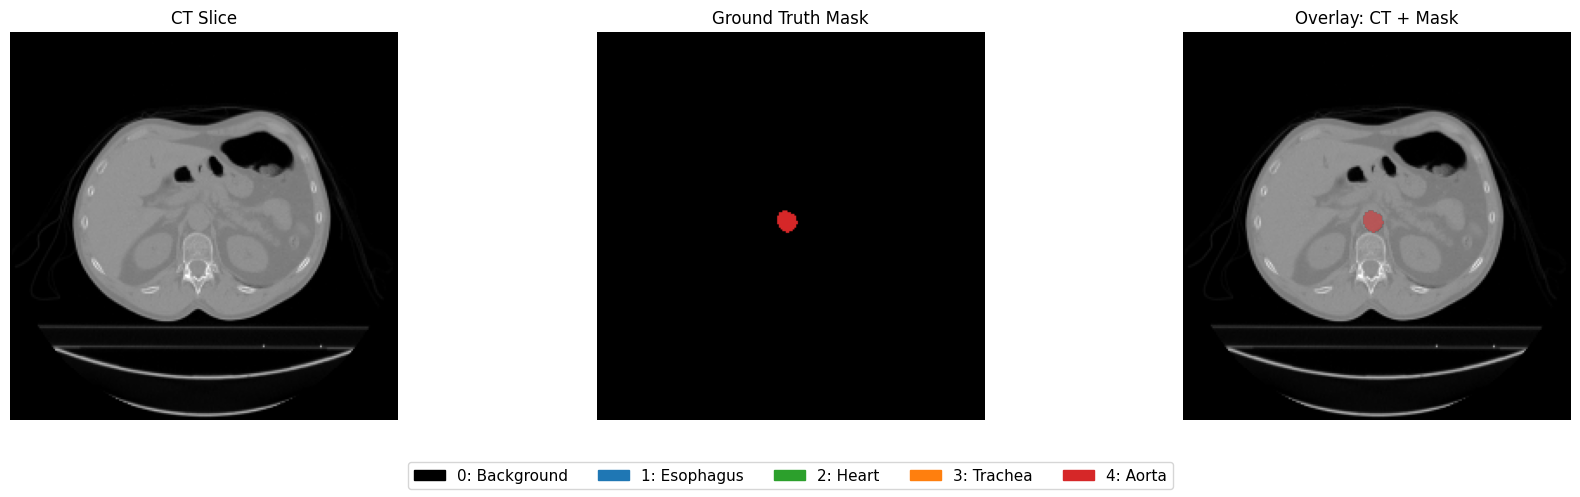

In [16]:
# ==========================================================
# Cell 14B: Verify a Foreground Slice with Organ Color Legend
# ==========================================================

import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm

# ----------------------------------------------------------
# Define label-to-organ mapping and colors
# ----------------------------------------------------------
label_info = {
    0: {"name": "Background", "color": "black"},
    1: {"name": "Esophagus",  "color": "#1f77b4"},  # Blue
    2: {"name": "Heart",      "color": "#2ca02c"},  # Green
    3: {"name": "Trachea",    "color": "#ff7f0e"},  # Orange
    4: {"name": "Aorta",      "color": "#d62728"},  # Red
}

mask_colors = [label_info[i]["color"] for i in range(5)]
mask_cmap = ListedColormap(mask_colors)
mask_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], mask_cmap.N)

# ----------------------------------------------------------
# Find first slice containing foreground organs
# ----------------------------------------------------------
foreground_found = False

for idx in range(len(train_slice_dataset)):

    patient, slice_idx = train_slice_dataset.slice_index[idx]
    image_volume, mask_volume = train_slice_dataset._load_volume(patient)

    mask_slice = mask_volume[slice_idx]

    if np.any(mask_slice > 0):
        foreground_found = True
        fg_idx = idx
        fg_patient = patient
        fg_slice_idx = slice_idx
        fg_labels = np.unique(mask_slice)
        fg_pixels = np.sum(mask_slice > 0)
        break

print("=" * 60)
print("FOREGROUND SLICE CHECK")
print("=" * 60)

if foreground_found:
    print("Foreground slice found ✅")
    print("Dataset Index :", fg_idx)
    print("Patient       :", fg_patient)
    print("Slice Index   :", fg_slice_idx)
    print("Labels        :", fg_labels)
    print("FG Pixels     :", fg_pixels)

    print("\nColor-wise Organ Representation")
    print("-" * 60)
    for label, info in label_info.items():
        print(f"Label {label}: {info['name']}")

    image_volume, mask_volume = train_slice_dataset._load_volume(fg_patient)

    image_slice = image_volume[fg_slice_idx]
    mask_slice = mask_volume[fg_slice_idx]

    # Mask background for overlay so only organs are colored
    masked_overlay = np.ma.masked_where(mask_slice == 0, mask_slice)

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))

    # CT image
    ax[0].imshow(image_slice, cmap="gray")
    ax[0].set_title("CT Slice")
    ax[0].axis("off")

    # Mask only
    ax[1].imshow(mask_slice, cmap=mask_cmap, norm=mask_norm)
    ax[1].set_title("Ground Truth Mask")
    ax[1].axis("off")

    # Overlay
    ax[2].imshow(image_slice, cmap="gray")
    ax[2].imshow(masked_overlay, cmap=mask_cmap, norm=mask_norm, alpha=0.55)
    ax[2].set_title("Overlay: CT + Mask")
    ax[2].axis("off")

    # Legend
    legend_patches = [
        mpatches.Patch(
            color=label_info[label]["color"],
            label=f"{label}: {label_info[label]['name']}"
        )
        for label in label_info
    ]

    fig.legend(
        handles=legend_patches,
        loc="lower center",
        ncol=5,
        fontsize=11,
        frameon=True
    )

    plt.tight_layout(rect=[0, 0.12, 1, 1])
    plt.show()

else:
    print("No foreground slice found ❌")

In [17]:
# ==========================================================
# Cell 15: DataLoaders
# ==========================================================

train_loader = DataLoader(
    train_slice_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=True,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=cfg.PIN_MEMORY,
    drop_last=True
)

val_loader = DataLoader(
    val_slice_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=cfg.PIN_MEMORY,
    drop_last=False
)

print("=" * 60)
print("DATALOADER VERIFICATION")
print("=" * 60)

print(f"Train Batches : {len(train_loader)}")
print(f"Val Batches   : {len(val_loader)}")

batch_images, batch_masks = next(iter(train_loader))

print("\nBatch Image Shape :", batch_images.shape)
print("Batch Mask Shape  :", batch_masks.shape)

print("\nBatch Image dtype :", batch_images.dtype)
print("Batch Mask dtype  :", batch_masks.dtype)

print("\nBatch Image Range")
print(f"Min : {batch_images.min():.4f}")
print(f"Max : {batch_images.max():.4f}")

print("\nBatch Mask Labels")
print(torch.unique(batch_masks))

DATALOADER VERIFICATION
Train Batches : 727
Val Batches   : 201

Batch Image Shape : torch.Size([8, 1, 224, 224])
Batch Mask Shape  : torch.Size([8, 224, 224])

Batch Image dtype : torch.float32
Batch Mask dtype  : torch.int64

Batch Image Range
Min : 0.0000
Max : 1.0000

Batch Mask Labels
tensor([0, 1, 3, 4])


In [18]:
# ==========================================================
# Cell 16: U-Net Baseline Model
# ==========================================================

class DoubleConv(nn.Module):
    """
    Two consecutive convolution layers:
    Conv -> BatchNorm -> ReLU -> Conv -> BatchNorm -> ReLU
    """

    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """
    Standard 2D U-Net for medical image segmentation.
    Input : [B, 1, 224, 224]
    Output: [B, NUM_CLASSES, 224, 224]
    """

    def __init__(self, in_channels=1, num_classes=5, base_channels=32):
        super(UNet, self).__init__()

        self.enc1 = DoubleConv(in_channels, base_channels)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = DoubleConv(base_channels, base_channels * 2)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = DoubleConv(base_channels * 2, base_channels * 4)
        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = DoubleConv(base_channels * 4, base_channels * 8)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base_channels * 8, base_channels * 16)

        self.up4 = nn.ConvTranspose2d(base_channels * 16, base_channels * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(base_channels * 16, base_channels * 8)

        self.up3 = nn.ConvTranspose2d(base_channels * 8, base_channels * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base_channels * 8, base_channels * 4)

        self.up2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base_channels * 4, base_channels * 2)

        self.up1 = nn.ConvTranspose2d(base_channels * 2, base_channels, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base_channels * 2, base_channels)

        self.out_conv = nn.Conv2d(base_channels, num_classes, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        output = self.out_conv(d1)

        return output


print("U-Net model class created successfully.")

U-Net model class created successfully.


In [19]:
# ==========================================================
# Cell 17: U-Net Forward Pass Verification
# ==========================================================

unet_model = UNet(
    in_channels=1,
    num_classes=cfg.NUM_CLASSES,
    base_channels=32
).to(device)

# Get one batch
images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = unet_model(images)

print("=" * 60)
print("U-NET FORWARD PASS CHECK")
print("=" * 60)

print("Input Image Shape :", images.shape)
print("Target Mask Shape :", masks.shape)
print("Model Output Shape:", outputs.shape)

print("\nOutput dtype:", outputs.dtype)

total_params = sum(p.numel() for p in unet_model.parameters())
trainable_params = sum(p.numel() for p in unet_model.parameters() if p.requires_grad)

print("\nModel Parameters")
print("-" * 60)
print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

U-NET FORWARD PASS CHECK
Input Image Shape : torch.Size([8, 1, 224, 224])
Target Mask Shape : torch.Size([8, 224, 224])
Model Output Shape: torch.Size([8, 5, 224, 224])

Output dtype: torch.float32

Model Parameters
------------------------------------------------------------
Total Parameters     : 7,762,597
Trainable Parameters : 7,762,597


In [20]:
# ==========================================================
# Cell 18: Loss Function and Dice Metric
# ==========================================================

class DiceLoss(nn.Module):
    """
    Multi-class Dice Loss.
    Background class can be excluded to focus learning on organs.
    """

    def __init__(self, num_classes=5, smooth=1e-5, exclude_background=True):
        super(DiceLoss, self).__init__()

        self.num_classes = num_classes
        self.smooth = smooth
        self.exclude_background = exclude_background

    def forward(self, logits, targets):

        # logits: [B, C, H, W]
        # targets: [B, H, W]

        probs = torch.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).permute(0, 3, 1, 2).float()

        if self.exclude_background:
            probs = probs[:, 1:, :, :]
            targets_one_hot = targets_one_hot[:, 1:, :, :]

        dims = (0, 2, 3)

        intersection = torch.sum(probs * targets_one_hot, dims)
        denominator = torch.sum(probs + targets_one_hot, dims)

        dice = (2.0 * intersection + self.smooth) / (denominator + self.smooth)

        loss = 1.0 - dice.mean()

        return loss


class CombinedLoss(nn.Module):
    """
    CrossEntropy Loss + Dice Loss.
    CE helps pixel-wise classification.
    Dice helps with class imbalance.
    """

    def __init__(self, num_classes=5, ce_weight=0.5, dice_weight=0.5):
        super(CombinedLoss, self).__init__()

        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(
            num_classes=num_classes,
            exclude_background=True
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)

        total_loss = self.ce_weight * ce + self.dice_weight * dice

        return total_loss


def dice_score_from_logits(logits, targets, num_classes=5, exclude_background=True, smooth=1e-5):
    """
    Computes mean Dice score from logits.
    Used for monitoring training/validation.
    """

    preds = torch.argmax(logits, dim=1)

    start_class = 1 if exclude_background else 0

    dice_scores = []

    for cls in range(start_class, num_classes):

        pred_cls = (preds == cls).float()
        target_cls = (targets == cls).float()

        intersection = torch.sum(pred_cls * target_cls)
        denominator = torch.sum(pred_cls) + torch.sum(target_cls)

        if denominator == 0:
            continue

        dice = (2.0 * intersection + smooth) / (denominator + smooth)
        dice_scores.append(dice)

    if len(dice_scores) == 0:
        return torch.tensor(0.0, device=logits.device)

    return torch.mean(torch.stack(dice_scores))


criterion = CombinedLoss(
    num_classes=cfg.NUM_CLASSES,
    ce_weight=0.5,
    dice_weight=0.5
)

print("=" * 60)
print("LOSS FUNCTION CREATED")
print("=" * 60)
print("Loss: 0.5 * CrossEntropy + 0.5 * DiceLoss")
print("Dice excludes background class.")

LOSS FUNCTION CREATED
Loss: 0.5 * CrossEntropy + 0.5 * DiceLoss
Dice excludes background class.


In [21]:
# ==========================================================
# Cell 19: Loss and Dice Sanity Check
# ==========================================================

unet_model.eval()

images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = unet_model(images)

    loss_value = criterion(outputs, masks)
    dice_value = dice_score_from_logits(
        outputs,
        masks,
        num_classes=cfg.NUM_CLASSES,
        exclude_background=True
    )

print("=" * 60)
print("LOSS / METRIC SANITY CHECK")
print("=" * 60)

print("Output Shape :", outputs.shape)
print("Mask Shape   :", masks.shape)

print(f"\nLoss Value   : {loss_value.item():.6f}")
print(f"Dice Score   : {dice_value.item():.6f}")

print("\nBatch Mask Labels:")
print(torch.unique(masks))

LOSS / METRIC SANITY CHECK
Output Shape : torch.Size([8, 5, 224, 224])
Mask Shape   : torch.Size([8, 224, 224])

Loss Value   : 1.306573
Dice Score   : 0.000727

Batch Mask Labels:
tensor([0, 1, 2, 4], device='cuda:0')


In [22]:
# ==========================================================
# Cell 20: Training Configuration
# ==========================================================

# Optimizer settings
cfg.OPTIMIZER = "SGD"
cfg.MOMENTUM = 0.9

# Poly LR Scheduler
cfg.POLY_POWER = 0.9

# Mixed precision for faster GPU training
cfg.USE_AMP = True if torch.cuda.is_available() else False

# Checkpoint directory
cfg.CHECKPOINT_DIR = "/kaggle/working/checkpoints"
os.makedirs(cfg.CHECKPOINT_DIR, exist_ok=True)

print("=" * 60)
print("TRAINING CONFIGURATION")
print("=" * 60)
print("Optimizer       :", cfg.OPTIMIZER)
print("Learning Rate   :", cfg.LR)
print("Momentum        :", cfg.MOMENTUM)
print("Weight Decay    :", cfg.WEIGHT_DECAY)
print("Poly Power      :", cfg.POLY_POWER)
print("AMP Enabled     :", cfg.USE_AMP)
print("Checkpoint Dir  :", cfg.CHECKPOINT_DIR)

TRAINING CONFIGURATION
Optimizer       : SGD
Learning Rate   : 0.01
Momentum        : 0.9
Weight Decay    : 0.0001
Poly Power      : 0.9
AMP Enabled     : True
Checkpoint Dir  : /kaggle/working/checkpoints


In [23]:
# ==========================================================
# Cell 21: Optimizer and Poly LR Scheduler
# ==========================================================

def create_optimizer(model):
    """
    Creates optimizer for model training.
    """

    optimizer = optim.SGD(
        model.parameters(),
        lr=cfg.LR,
        momentum=cfg.MOMENTUM,
        weight_decay=cfg.WEIGHT_DECAY
    )

    return optimizer


class PolyLRScheduler:
    """
    Poly Learning Rate Scheduler.

    lr = initial_lr * (1 - current_iter / max_iter) ^ power
    """

    def __init__(self, optimizer, max_iters, power=0.9):

        self.optimizer = optimizer
        self.max_iters = max_iters
        self.power = power
        self.current_iter = 0

        self.initial_lrs = [
            group["lr"] for group in optimizer.param_groups
        ]

    def step(self):

        self.current_iter += 1

        for i, param_group in enumerate(self.optimizer.param_groups):

            lr = self.initial_lrs[i] * (
                1 - self.current_iter / self.max_iters
            ) ** self.power

            param_group["lr"] = max(lr, 1e-8)

    def get_lr(self):
        return self.optimizer.param_groups[0]["lr"]


print("Optimizer creator and Poly LR scheduler created successfully.")

Optimizer creator and Poly LR scheduler created successfully.


In [29]:
# ==========================================================
# Cell 22: Corrected Training and Validation Functions
# ==========================================================

ORGAN_NAMES = {
    1: "Esophagus",
    2: "Heart",
    3: "Trachea",
    4: "Aorta"
}


def calculate_epoch_dice(
    intersections,
    denominators,
    num_classes=5
):
    """
    Calculate per-organ and mean Dice from accumulated
    epoch-level statistics.

    Background class 0 is excluded.
    """

    class_dice = {}
    dice_values = []

    for cls in range(1, num_classes):

        if denominators[cls].item() > 0:

            dice = (
                2.0 * intersections[cls] + 1e-5
            ) / (
                denominators[cls] + 1e-5
            )

            dice_value = dice.item()

        else:
            dice_value = float("nan")

        class_dice[ORGAN_NAMES[cls]] = dice_value

        if not np.isnan(dice_value):
            dice_values.append(dice_value)

    mean_dice = (
        float(np.mean(dice_values))
        if len(dice_values) > 0
        else 0.0
    )

    return mean_dice, class_dice


# ==========================================================
# Training Function
# ==========================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scheduler,
    scaler,
    device
):

    model.train()

    running_loss = 0.0

    # Global epoch statistics
    intersections = torch.zeros(
        cfg.NUM_CLASSES,
        device=device,
        dtype=torch.float64
    )

    denominators = torch.zeros(
        cfg.NUM_CLASSES,
        device=device,
        dtype=torch.float64
    )

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, masks in progress_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # Modern AMP API
        with torch.amp.autocast(
            device_type=device.type,
            enabled=cfg.USE_AMP
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                masks
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        scheduler.step()

        running_loss += loss.item()

        # ----------------------------------
        # Accumulate global Dice statistics
        # ----------------------------------
        with torch.no_grad():

            preds = torch.argmax(
                outputs,
                dim=1
            )

            for cls in range(
                1,
                cfg.NUM_CLASSES
            ):

                pred_cls = (
                    preds == cls
                )

                mask_cls = (
                    masks == cls
                )

                intersections[cls] += torch.sum(
                    pred_cls & mask_cls
                ).double()

                denominators[cls] += (
                    torch.sum(pred_cls).double()
                    +
                    torch.sum(mask_cls).double()
                )

        progress_bar.set_postfix({
            "loss": f"{loss.item():.4f}",
            "lr": f"{scheduler.get_lr():.6f}"
        })

    epoch_loss = (
        running_loss / len(loader)
    )

    epoch_dice, class_dice = calculate_epoch_dice(
        intersections,
        denominators,
        cfg.NUM_CLASSES
    )

    return (
        epoch_loss,
        epoch_dice,
        class_dice
    )


# ==========================================================
# Validation Function
# ==========================================================

def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    intersections = torch.zeros(
        cfg.NUM_CLASSES,
        device=device,
        dtype=torch.float64
    )

    denominators = torch.zeros(
        cfg.NUM_CLASSES,
        device=device,
        dtype=torch.float64
    )

    with torch.no_grad():

        progress_bar = tqdm(
            loader,
            desc="Validation",
            leave=False
        )

        for images, masks in progress_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            # Modern AMP API
            with torch.amp.autocast(
                device_type=device.type,
                enabled=cfg.USE_AMP
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    masks
                )

            running_loss += loss.item()

            preds = torch.argmax(
                outputs,
                dim=1
            )

            for cls in range(
                1,
                cfg.NUM_CLASSES
            ):

                pred_cls = (
                    preds == cls
                )

                mask_cls = (
                    masks == cls
                )

                intersections[cls] += torch.sum(
                    pred_cls & mask_cls
                ).double()

                denominators[cls] += (
                    torch.sum(pred_cls).double()
                    +
                    torch.sum(mask_cls).double()
                )

    epoch_loss = (
        running_loss / len(loader)
    )

    mean_dice, class_dice = calculate_epoch_dice(
        intersections,
        denominators,
        cfg.NUM_CLASSES
    )

    return (
        epoch_loss,
        mean_dice,
        class_dice
    )


print("=" * 60)
print("Corrected training and validation functions created ✅")
print("=" * 60)
print("Train Dice and Val Dice now use matching aggregation.")
print("Modern torch.amp.autocast API enabled.")

Corrected training and validation functions created ✅
Train Dice and Val Dice now use matching aggregation.
Modern torch.amp.autocast API enabled.


In [30]:
# ==========================================================
# Cell 22B: Early Stopping Configuration
# ==========================================================

cfg.USE_EARLY_STOPPING = True

# Stop if validation Dice does not improve for 25 epochs
cfg.EARLY_STOPPING_PATIENCE = 25

# Minimum meaningful Dice improvement
cfg.MIN_DELTA = 1e-4

print("=" * 60)
print("EARLY STOPPING CONFIGURATION")
print("=" * 60)

print(
    "Enabled  :",
    cfg.USE_EARLY_STOPPING
)

print(
    "Patience :",
    cfg.EARLY_STOPPING_PATIENCE
)

print(
    "Min Delta:",
    cfg.MIN_DELTA
)

EARLY STOPPING CONFIGURATION
Enabled  : True
Patience : 25
Min Delta: 0.0001


In [31]:
# ==========================================================
# Cell 23: Corrected Universal Training Engine
# ==========================================================

import pandas as pd


def get_config_dict(cfg):
    """
    Safely collect all public configuration values.
    """

    config_dict = {}

    for key in dir(cfg):

        if key.startswith("_"):
            continue

        value = getattr(cfg, key)

        if callable(value):
            continue

        config_dict[key] = value

    return config_dict


def train_model(
    model,
    model_name,
    train_loader,
    val_loader,
    epochs
):

    model = model.to(device)

    optimizer = create_optimizer(model)

    max_iters = (
        len(train_loader) * epochs
    )

    scheduler = PolyLRScheduler(
        optimizer=optimizer,
        max_iters=max_iters,
        power=cfg.POLY_POWER
    )

    # Modern AMP GradScaler API
    scaler = torch.amp.GradScaler(
        device.type,
        enabled=cfg.USE_AMP
    )

    best_val_dice = -float("inf")
    best_epoch = 0

    epochs_without_improvement = 0

    history = []

    checkpoint_path = os.path.join(
        cfg.CHECKPOINT_DIR,
        f"{model_name}_best.pth"
    )

    history_path = os.path.join(
        cfg.CHECKPOINT_DIR,
        f"{model_name}_history.csv"
    )

    print("=" * 60)
    print(f"START TRAINING: {model_name}")
    print("=" * 60)

    for epoch in range(
        1,
        epochs + 1
    ):

        start_time = time.time()

        # ==================================
        # Training
        # ==================================

        (
            train_loss,
            train_dice,
            train_class_dice
        ) = train_one_epoch(

            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            scheduler=scheduler,
            scaler=scaler,
            device=device
        )

        # ==================================
        # Validation
        # ==================================

        (
            val_loss,
            val_dice,
            val_class_dice
        ) = validate_one_epoch(

            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device
        )

        epoch_time = (
            time.time() - start_time
        )

        current_lr = (
            scheduler.get_lr()
        )

        # ==================================
        # Store History
        # ==================================

        history.append({

            "epoch": epoch,

            "train_loss": train_loss,
            "train_dice": train_dice,

            "val_loss": val_loss,
            "val_dice": val_dice,

            "lr": current_lr,
            "time_sec": epoch_time,

            # Validation per-organ Dice
            "dice_esophagus":
                val_class_dice["Esophagus"],

            "dice_heart":
                val_class_dice["Heart"],

            "dice_trachea":
                val_class_dice["Trachea"],

            "dice_aorta":
                val_class_dice["Aorta"]
        })

        # ==================================
        # Epoch Log
        # ==================================

        print(
            f"Epoch [{epoch:03d}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Dice: {train_dice:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Dice: {val_dice:.4f} | "
            f"LR: {current_lr:.6f} | "
            f"Time: {epoch_time:.1f}s"
        )

        print(
            "  Val Organ Dice -> "
            f"Eso: {val_class_dice['Esophagus']:.4f}, "
            f"Heart: {val_class_dice['Heart']:.4f}, "
            f"Trachea: {val_class_dice['Trachea']:.4f}, "
            f"Aorta: {val_class_dice['Aorta']:.4f}"
        )

        # ==================================
        # Best Model Check
        # ==================================

        improved = (
            val_dice
            >
            best_val_dice + cfg.MIN_DELTA
        )

        if improved:

            best_val_dice = val_dice
            best_epoch = epoch

            epochs_without_improvement = 0

            torch.save({

                "epoch":
                    epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "model_name":
                    model_name,

                "config":
                    get_config_dict(cfg)

            }, checkpoint_path)

            print(
                f"  ✅ Best model saved! "
                f"Val Dice: {best_val_dice:.4f}"
            )

        else:

            epochs_without_improvement += 1

            print(
                f"  No improvement: "
                f"{epochs_without_improvement}/"
                f"{cfg.EARLY_STOPPING_PATIENCE}"
            )

        # ==================================
        # Save History Every Epoch
        # ==================================

        history_df = pd.DataFrame(
            history
        )

        history_df.to_csv(
            history_path,
            index=False
        )

        # ==================================
        # Early Stopping
        # ==================================

        if (
            cfg.USE_EARLY_STOPPING
            and
            epochs_without_improvement
            >=
            cfg.EARLY_STOPPING_PATIENCE
        ):

            print("\n" + "=" * 60)
            print("EARLY STOPPING TRIGGERED")
            print("=" * 60)

            print(
                f"Best Epoch      : {best_epoch}"
            )

            print(
                f"Best Val Dice   : {best_val_dice:.4f}"
            )

            break

    # ==================================
    # Final Summary
    # ==================================

    history_df = pd.DataFrame(
        history
    )

    print("\n" + "=" * 60)
    print(
        f"TRAINING COMPLETED: {model_name}"
    )
    print("=" * 60)

    print(
        f"Best Epoch           : {best_epoch}"
    )

    print(
        f"Best Validation Dice : {best_val_dice:.4f}"
    )

    print(
        f"Checkpoint           : {checkpoint_path}"
    )

    print(
        f"History CSV          : {history_path}"
    )

    return (
        model,
        history_df,
        checkpoint_path
    )


print("=" * 60)
print("Corrected universal training engine created ✅")
print("=" * 60)

Corrected universal training engine created ✅


In [32]:
# ==========================================================
# Cell 24: Corrected One-Epoch U-Net Sanity Training
# ==========================================================

# Fresh model
unet_sanity_model = UNet(
    in_channels=1,
    num_classes=cfg.NUM_CLASSES,
    base_channels=32
)

(
    unet_sanity_model,
    unet_sanity_history,
    unet_sanity_ckpt
) = train_model(

    model=unet_sanity_model,

    model_name="unet_sanity_v2",

    train_loader=train_loader,

    val_loader=val_loader,

    epochs=1
)

display(
    unet_sanity_history
)

START TRAINING: unet_sanity_v2


Epoch [001/1] | Train Loss: 0.5337 | Train Dice: 0.0383 | Val Loss: 0.5009 | Val Dice: 0.1419 | LR: 0.000000 | Time: 62.6s
  Val Organ Dice -> Eso: 0.0000, Heart: 0.5677, Trachea: 0.0000, Aorta: 0.0000
  ✅ Best model saved! Val Dice: 0.1419

TRAINING COMPLETED: unet_sanity_v2
Best Epoch           : 1
Best Validation Dice : 0.1419
Checkpoint           : /kaggle/working/checkpoints/unet_sanity_v2_best.pth
History CSV          : /kaggle/working/checkpoints/unet_sanity_v2_history.csv


,epoch,train_loss,train_dice,val_loss,val_dice,lr,time_sec,dice_esophagus,dice_heart,dice_trachea,dice_aorta
0,1,0.533749,0.038346,0.500904,0.141928,1.000000e-08,62.640601,3.051385e-10,0.567712,4.106270e-10,7.407462e-11


In [33]:
# ==========================================================
# Cell 25: Full U-Net Training
# ==========================================================

# Free sanity-model GPU memory
del unet_sanity_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ----------------------------------------------------------
# Fresh U-Net model
# ----------------------------------------------------------

unet_model = UNet(
    in_channels=1,
    num_classes=cfg.NUM_CLASSES,
    base_channels=32
)


print("=" * 60)
print("FULL U-NET TRAINING")
print("=" * 60)

print("Maximum Epochs :", cfg.EPOCHS)
print(
    "Early Stopping:",
    cfg.USE_EARLY_STOPPING
)
print(
    "Patience      :",
    cfg.EARLY_STOPPING_PATIENCE
)


# ----------------------------------------------------------
# Train
# ----------------------------------------------------------

(
    unet_model,
    unet_history,
    unet_checkpoint
) = train_model(

    model=unet_model,

    model_name="unet",

    train_loader=train_loader,

    val_loader=val_loader,

    epochs=cfg.EPOCHS
)


print("\nU-Net training finished ✅")

print(
    "Best checkpoint:",
    unet_checkpoint
)

FULL U-NET TRAINING
Maximum Epochs : 220
Early Stopping: True
Patience      : 25
START TRAINING: unet


Epoch [001/220] | Train Loss: 0.5237 | Train Dice: 0.0595 | Val Loss: 0.4968 | Val Dice: 0.1532 | LR: 0.009959 | Time: 62.6s
  Val Organ Dice -> Eso: 0.0000, Heart: 0.6129, Trachea: 0.0000, Aorta: 0.0000
  ✅ Best model saved! Val Dice: 0.1532


Epoch [002/220] | Train Loss: 0.4169 | Train Dice: 0.2658 | Val Loss: 0.4698 | Val Dice: 0.3470 | LR: 0.009918 | Time: 60.9s
  Val Organ Dice -> Eso: 0.0000, Heart: 0.6602, Trachea: 0.3968, Aorta: 0.3310
  ✅ Best model saved! Val Dice: 0.3470


Epoch [003/220] | Train Loss: 0.2799 | Train Dice: 0.5435 | Val Loss: 0.4269 | Val Dice: 0.5712 | LR: 0.009877 | Time: 61.1s
  Val Organ Dice -> Eso: 0.3228, Heart: 0.7141, Trachea: 0.6738, Aorta: 0.5739
  ✅ Best model saved! Val Dice: 0.5712


Epoch [004/220] | Train Loss: 0.2076 | Train Dice: 0.6679 | Val Loss: 0.4070 | Val Dice: 0.6457 | LR: 0.009836 | Time: 61.6s
  Val Organ Dice -> Eso: 0.4029, Heart: 0.7996, Trachea: 0.6864, Aorta: 0.6938
  ✅ Best model saved! Val Dice: 0.6457


...

Epoch [134/220] | Train Loss: 0.0678 | Train Dice: 0.9333 | Val Loss: 0.3601 | Val Dice: 0.8110 | LR: 0.004294 | Time: 61.3s
  Val Organ Dice -> Eso: 0.6520, Heart: 0.8790, Trachea: 0.8214, Aorta: 0.8917
  No improvement: 21/25


Epoch [135/220] | Train Loss: 0.0670 | Train Dice: 0.9317 | Val Loss: 0.3587 | Val Dice: 0.8141 | LR: 0.004249 | Time: 61.4s
  Val Organ Dice -> Eso: 0.6572, Heart: 0.8870, Trachea: 0.8236, Aorta: 0.8886
  No improvement: 22/25


Epoch [136/220] | Train Loss: 0.0673 | Train Dice: 0.9300 | Val Loss: 0.3614 | Val Dice: 0.8051 | LR: 0.004204 | Time: 61.5s
  Val Organ Dice -> Eso: 0.6461, Heart: 0.8701, Trachea: 0.8155, Aorta: 0.8886
  No improvement: 23/25


Epoch [137/220] | Train Loss: 0.0651 | Train Dice: 0.9353 | Val Loss: 0.3607 | Val Dice: 0.8124 | LR: 0.004159 | Time: 61.6s
  Val Organ Dice -> Eso: 0.6690, Heart: 0.8550, Trachea: 0.8343, Aorta: 0.8913
  No improvement: 24/25


Epoch [138/220] | Train Loss: 0.0650 | Train Dice: 0.9352 | Val Loss: 0.3602 | Val Dice: 0.8193 | LR: 0.004114 | Time: 61.5s
  Val Organ Dice -> Eso: 0.6667, Heart: 0.8926, Trachea: 0.8262, Aorta: 0.8919
  No improvement: 25/25

EARLY STOPPING TRIGGERED
Best Epoch      : 113
Best Val Dice   : 0.8245

TRAINING COMPLETED: unet
Best Epoch           : 113
Best Validation Dice : 0.8245
Checkpoint           : /kaggle/working/checkpoints/unet_best.pth
History CSV          : /kaggle/working/checkpoints/unet_history.csv

U-Net training finished ✅
Best checkpoint: /kaggle/working/checkpoints/unet_best.pth


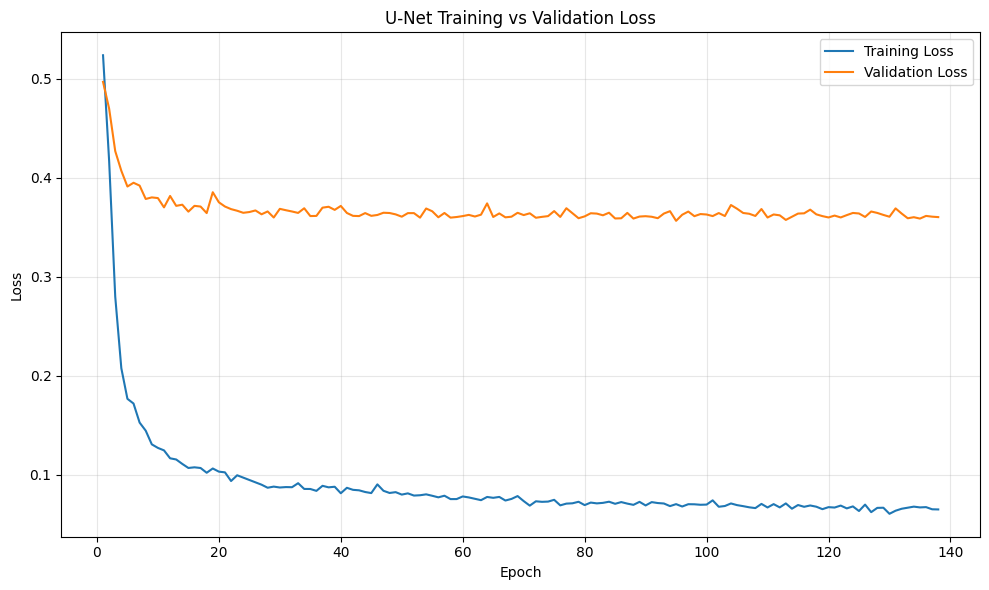

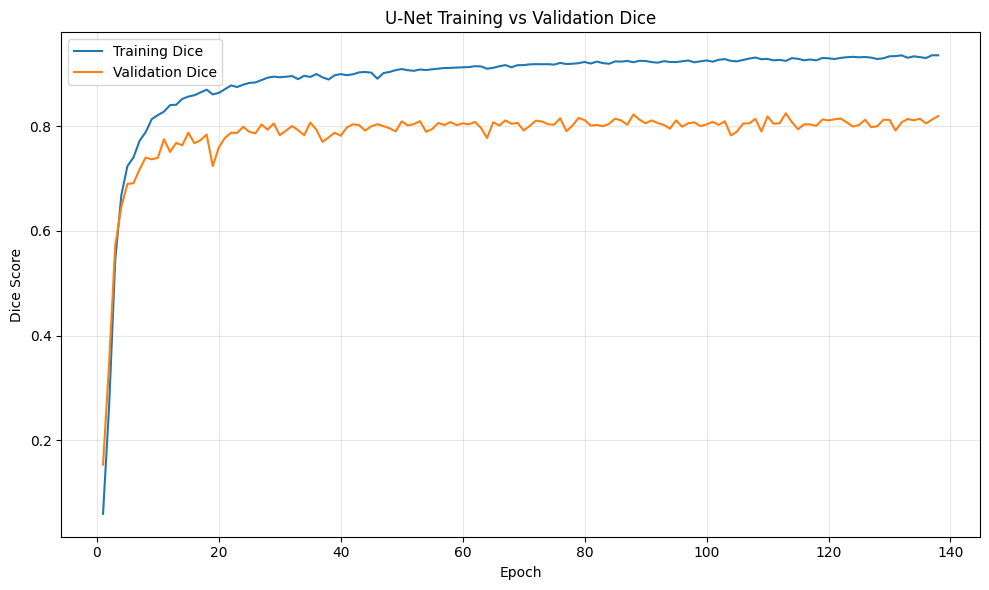

BEST U-NET EPOCH
Epoch          : 113
Train Loss     : 0.071035
Train Dice     : 0.924513
Validation Loss: 0.357383
Validation Dice: 0.824542

Per-Organ Validation Dice
------------------------------------------------------------
Esophagus : 0.666903
Heart     : 0.904976
Trachea   : 0.827967
Aorta     : 0.898321


In [34]:
# ==========================================================
# Cell 26: U-Net Learning Curves
# ==========================================================

import matplotlib.pyplot as plt


# ----------------------------------------------------------
# Loss Curve
# ----------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    unet_history["epoch"],
    unet_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    unet_history["epoch"],
    unet_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "U-Net Training vs Validation Loss"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Dice Curve
# ----------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    unet_history["epoch"],
    unet_history["train_dice"],
    label="Training Dice"
)

plt.plot(
    unet_history["epoch"],
    unet_history["val_dice"],
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Score")

plt.title(
    "U-Net Training vs Validation Dice"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Best Epoch Summary
# ----------------------------------------------------------

best_row = unet_history.loc[
    unet_history["val_dice"].idxmax()
]

print("=" * 60)
print("BEST U-NET EPOCH")
print("=" * 60)

print(
    f"Epoch          : "
    f"{int(best_row['epoch'])}"
)

print(
    f"Train Loss     : "
    f"{best_row['train_loss']:.6f}"
)

print(
    f"Train Dice     : "
    f"{best_row['train_dice']:.6f}"
)

print(
    f"Validation Loss: "
    f"{best_row['val_loss']:.6f}"
)

print(
    f"Validation Dice: "
    f"{best_row['val_dice']:.6f}"
)

print("\nPer-Organ Validation Dice")
print("-" * 60)

print(
    f"Esophagus : "
    f"{best_row['dice_esophagus']:.6f}"
)

print(
    f"Heart     : "
    f"{best_row['dice_heart']:.6f}"
)

print(
    f"Trachea   : "
    f"{best_row['dice_trachea']:.6f}"
)

print(
    f"Aorta     : "
    f"{best_row['dice_aorta']:.6f}"
)

In [35]:
# ==========================================================
# Cell 27: Load Best U-Net Checkpoint
# ==========================================================

BEST_UNET_PATH = "/kaggle/working/checkpoints/unet_best.pth"

assert os.path.exists(BEST_UNET_PATH), (
    f"Checkpoint not found: {BEST_UNET_PATH}"
)

# Fresh model
best_unet_model = UNet(
    in_channels=1,
    num_classes=cfg.NUM_CLASSES,
    base_channels=32
).to(device)

# Load complete checkpoint
checkpoint = torch.load(
    BEST_UNET_PATH,
    map_location=device,
    weights_only=False
)

best_unet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_unet_model.eval()

print("=" * 60)
print("BEST U-NET CHECKPOINT LOADED")
print("=" * 60)

print("Checkpoint Path :", BEST_UNET_PATH)
print("Best Epoch      :", checkpoint["epoch"])
print(
    "Best Val Dice   :",
    f"{checkpoint['best_val_dice']:.6f}"
)

print("\nModel ready for 3D evaluation ✅")

BEST U-NET CHECKPOINT LOADED
Checkpoint Path : /kaggle/working/checkpoints/unet_best.pth
Best Epoch      : 113
Best Val Dice   : 0.824542

Model ready for 3D evaluation ✅


In [36]:
# ==========================================================
# Cell 28: 3D Dice + Exact Hausdorff Distance in mm
# ==========================================================

from scipy.ndimage import (
    binary_erosion,
    distance_transform_edt,
    generate_binary_structure
)


ORGAN_NAMES = {
    1: "Esophagus",
    2: "Heart",
    3: "Trachea",
    4: "Aorta"
}


# ----------------------------------------------------------
# 3D Dice
# ----------------------------------------------------------

def dice_3d(pred_binary, gt_binary, smooth=1e-5):
    """
    Computes Dice score between two 3D binary volumes.
    """

    pred_binary = pred_binary.astype(bool)
    gt_binary = gt_binary.astype(bool)

    intersection = np.logical_and(
        pred_binary,
        gt_binary
    ).sum()

    denominator = (
        pred_binary.sum()
        +
        gt_binary.sum()
    )

    # Both masks empty
    if denominator == 0:
        return 1.0

    dice = (
        2.0 * intersection + smooth
    ) / (
        denominator + smooth
    )

    return float(dice)


# ----------------------------------------------------------
# Extract 3D surface
# ----------------------------------------------------------

def extract_surface(binary_mask):
    """
    Extracts the boundary/surface voxels of a 3D binary mask.
    """

    binary_mask = binary_mask.astype(bool)

    structure = generate_binary_structure(
        rank=3,
        connectivity=1
    )

    eroded = binary_erosion(
        binary_mask,
        structure=structure,
        border_value=0
    )

    surface = np.logical_xor(
        binary_mask,
        eroded
    )

    return surface


# ----------------------------------------------------------
# Exact Symmetric Hausdorff Distance
# ----------------------------------------------------------

def hausdorff_distance_3d_mm(
    pred_binary,
    gt_binary,
    spacing_zyx
):
    """
    Exact symmetric 3D Hausdorff Distance in millimeters.

    Parameters
    ----------
    pred_binary : ndarray [D,H,W]
    gt_binary   : ndarray [D,H,W]

    spacing_zyx :
        Physical voxel spacing corresponding to
        NumPy array order (Z,Y,X).

    Returns
    -------
    HD in millimeters.
    """

    pred_binary = pred_binary.astype(bool)
    gt_binary = gt_binary.astype(bool)

    pred_exists = np.any(pred_binary)
    gt_exists = np.any(gt_binary)

    # Both empty
    if not pred_exists and not gt_exists:
        return 0.0

    # One empty, one non-empty:
    # HD is mathematically undefined/infinite.
    if pred_exists != gt_exists:
        return np.inf

    pred_surface = extract_surface(
        pred_binary
    )

    gt_surface = extract_surface(
        gt_binary
    )

    # Distance from every voxel to nearest GT surface
    distance_to_gt = distance_transform_edt(
        np.logical_not(gt_surface),
        sampling=spacing_zyx
    )

    # Distance from every voxel to nearest prediction surface
    distance_to_pred = distance_transform_edt(
        np.logical_not(pred_surface),
        sampling=spacing_zyx
    )

    pred_to_gt = distance_to_gt[
        pred_surface
    ]

    gt_to_pred = distance_to_pred[
        gt_surface
    ]

    hd = max(
        float(pred_to_gt.max()),
        float(gt_to_pred.max())
    )

    return hd


# ----------------------------------------------------------
# Correct spacing after 512 -> 224 resize
# ----------------------------------------------------------

def get_corrected_spacing_zyx(sitk_image):
    """
    Correct physical spacing after resizing:

        512 x 512 -> 224 x 224

    Stored SimpleITK spacing is in:
        (X, Y, Z)

    NumPy volume order is:
        (Z, Y, X)
    """

    spacing_x, spacing_y, spacing_z = (
        sitk_image.GetSpacing()
    )

    resize_factor = 512.0 / 224.0

    corrected_x = (
        spacing_x * resize_factor
    )

    corrected_y = (
        spacing_y * resize_factor
    )

    corrected_z = spacing_z

    # Return in NumPy array order
    return (
        corrected_z,
        corrected_y,
        corrected_x
    )


print("=" * 60)
print("3D EVALUATION METRICS CREATED")
print("=" * 60)

print("Metric 1 : 3D Dice Score")
print("Metric 2 : Exact Symmetric HD")
print("HD Unit  : millimeters (mm)")
print("Spacing  : Corrected for 512→224 resize")

3D EVALUATION METRICS CREATED
Metric 1 : 3D Dice Score
Metric 2 : Exact Symmetric HD
HD Unit  : millimeters (mm)
Spacing  : Corrected for 512→224 resize


In [37]:
# ==========================================================
# Cell 29: Universal Patient-wise 3D Evaluation Engine
# ==========================================================

import pandas as pd


def predict_full_volume(
    model,
    image_volume,
    device,
    batch_size=16
):
    """
    Slice-wise inference followed by 3D reconstruction.

    Input:
        image_volume [D,H,W]

    Output:
        prediction_volume [D,H,W]
    """

    model.eval()

    predictions = []

    with torch.no_grad():

        for start in range(
            0,
            image_volume.shape[0],
            batch_size
        ):

            end = min(
                start + batch_size,
                image_volume.shape[0]
            )

            batch_np = image_volume[
                start:end
            ]

            # [B,H,W] -> [B,1,H,W]
            batch_tensor = torch.from_numpy(
                batch_np
            ).unsqueeze(1).float()

            batch_tensor = batch_tensor.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type=device.type,
                enabled=cfg.USE_AMP
            ):

                logits = model(
                    batch_tensor
                )

            preds = torch.argmax(
                logits,
                dim=1
            )

            predictions.append(
                preds.cpu().numpy().astype(
                    np.uint8
                )
            )

    prediction_volume = np.concatenate(
        predictions,
        axis=0
    )

    return prediction_volume


def evaluate_model_3d(
    model,
    model_name,
    patient_list,
    dataset_path,
    device
):
    """
    Universal 3D patient-wise evaluation.

    Computes:
        - Per-organ 3D Dice
        - Per-organ exact HD in mm
    """

    all_records = []

    print("=" * 70)
    print(f"3D EVALUATION: {model_name}")
    print("=" * 70)

    for patient in tqdm(
        patient_list,
        desc=f"Evaluating {model_name}"
    ):

        patient_folder = os.path.join(
            dataset_path,
            patient
        )

        image_path = os.path.join(
            patient_folder,
            f"{patient}.nii.gz"
        )

        mask_path = os.path.join(
            patient_folder,
            "GT.nii.gz"
        )

        # ----------------------------------
        # Load patient
        # ----------------------------------

        image_sitk = sitk.ReadImage(
            image_path
        )

        mask_sitk = sitk.ReadImage(
            mask_path
        )

        image_np = sitk.GetArrayFromImage(
            image_sitk
        ).astype(np.float32)

        gt_np = sitk.GetArrayFromImage(
            mask_sitk
        ).astype(np.uint8)

        # ----------------------------------
        # Full-volume prediction
        # ----------------------------------

        pred_np = predict_full_volume(
            model=model,
            image_volume=image_np,
            device=device,
            batch_size=16
        )

        assert pred_np.shape == gt_np.shape, (
            f"Shape mismatch for {patient}: "
            f"{pred_np.shape} vs {gt_np.shape}"
        )

        # ----------------------------------
        # Correct physical spacing
        # ----------------------------------

        spacing_zyx = get_corrected_spacing_zyx(
            image_sitk
        )

        # ----------------------------------
        # Organ-wise metrics
        # ----------------------------------

        record = {
            "Model": model_name,
            "Patient": patient
        }

        patient_dice_values = []
        patient_hd_values = []

        for cls, organ_name in ORGAN_NAMES.items():

            pred_binary = (
                pred_np == cls
            )

            gt_binary = (
                gt_np == cls
            )

            dice_value = dice_3d(
                pred_binary,
                gt_binary
            )

            hd_value = hausdorff_distance_3d_mm(
                pred_binary,
                gt_binary,
                spacing_zyx
            )

            record[
                f"Dice_{organ_name}"
            ] = dice_value

            record[
                f"HD_{organ_name}_mm"
            ] = hd_value

            patient_dice_values.append(
                dice_value
            )

            if np.isfinite(hd_value):
                patient_hd_values.append(
                    hd_value
                )

        # Mean across 4 organs
        record["Mean_Dice"] = float(
            np.mean(patient_dice_values)
        )

        record["Mean_HD_mm"] = (
            float(np.mean(patient_hd_values))
            if len(patient_hd_values) > 0
            else np.inf
        )

        all_records.append(
            record
        )

        # Free memory
        del (
            image_np,
            gt_np,
            pred_np,
            image_sitk,
            mask_sitk
        )

        gc.collect()

    results_df = pd.DataFrame(
        all_records
    )

    return results_df


print(
    "Universal 3D evaluation engine created successfully ✅"
)

Universal 3D evaluation engine created successfully ✅


In [38]:
# ==========================================================
# Cell 30: Final 3D U-Net Evaluation
# ==========================================================

unet_3d_results = evaluate_model_3d(
    model=best_unet_model,
    model_name="U-Net",
    patient_list=val_patients,
    dataset_path=cfg.DATASET_PATH,
    device=device
)

print("\n" + "=" * 70)
print("PATIENT-WISE 3D RESULTS")
print("=" * 70)

display(
    unet_3d_results
)


# ----------------------------------------------------------
# Save patient-wise results
# ----------------------------------------------------------

UNET_RESULTS_PATH = (
    "/kaggle/working/checkpoints/"
    "unet_3d_dice_hd_results.csv"
)

unet_3d_results.to_csv(
    UNET_RESULTS_PATH,
    index=False
)

print(
    "\nPatient-wise results saved at:"
)
print(
    UNET_RESULTS_PATH
)

3D EVALUATION: U-Net


Evaluating U-Net: 100%|██████████| 8/8 [01:19<00:00,  9.99s/it]


PATIENT-WISE 3D RESULTS


,Model,Patient,Dice_Esophagus,HD_Esophagus_mm,Dice_Heart,HD_Heart_mm,Dice_Trachea,HD_Trachea_mm,Dice_Aorta,HD_Aorta_mm,Mean_Dice,Mean_HD_mm
0,U-Net,Patient_05,0.589553,26.848504,0.899628,322.421890,0.684470,139.986976,0.884006,20.582741,0.764414,127.460028
1,U-Net,Patient_13,0.681692,13.772593,0.940657,13.731771,0.885544,27.810148,0.927778,34.073193,0.858917,22.346926
2,U-Net,Patient_16,0.814550,18.575712,0.943167,235.921727,0.869259,8.137255,0.926579,11.826227,0.888389,68.615230
3,U-Net,Patient_17,0.690517,20.579330,0.957536,20.755997,0.850831,16.426872,0.889412,21.194588,0.847074,19.739197
4,U-Net,Patient_20,0.433973,107.392781,0.844795,335.748405,0.682884,46.586628,0.866428,18.424259,0.707020,127.038018
5,U-Net,Patient_27,0.782305,8.709747,0.944948,11.855865,0.902959,6.396273,0.917181,26.207017,0.886848,13.292226
6,U-Net,Patient_28,0.605353,33.514858,0.823170,32.500000,0.835622,17.182331,0.854308,46.716205,0.779613,32.478348
7,U-Net,Patient_38,0.664406,15.142019,0.930147,48.545558,0.915330,14.976591,0.902793,58.038709,0.853169,34.175719



Patient-wise results saved at:
/kaggle/working/checkpoints/unet_3d_dice_hd_results.csv


In [40]:
# ==========================================================
# Cell 31: Corrected Final Dice + HD Summary
# ==========================================================

summary_rows = []

# ----------------------------------------------------------
# Per-organ summary
# ----------------------------------------------------------

for cls, organ_name in ORGAN_NAMES.items():

    dice_col = f"Dice_{organ_name}"
    hd_col = f"HD_{organ_name}_mm"

    dice_values = unet_3d_results[
        dice_col
    ].astype(float)

    hd_values = unet_3d_results[
        hd_col
    ].replace(
        [np.inf, -np.inf],
        np.nan
    ).astype(float)

    summary_rows.append({

        "Organ": organ_name,

        "Mean_Dice":
            dice_values.mean(),

        "Std_Dice":
            dice_values.std(ddof=1),

        "Median_Dice":
            dice_values.median(),

        "Mean_HD_mm":
            hd_values.mean(),

        "Std_HD_mm":
            hd_values.std(ddof=1),

        "Median_HD_mm":
            hd_values.median(),

        "Valid_HD_Patients":
            hd_values.notna().sum(),

        "Failed_HD_Patients":
            hd_values.isna().sum()
    })


unet_summary = pd.DataFrame(
    summary_rows
)


# ----------------------------------------------------------
# TRUE overall patient-wise statistics
# ----------------------------------------------------------

patient_mean_dice = unet_3d_results[
    "Mean_Dice"
].astype(float)

patient_mean_hd = unet_3d_results[
    "Mean_HD_mm"
].replace(
    [np.inf, -np.inf],
    np.nan
).astype(float)


overall_row = {

    "Organ": "Overall",

    "Mean_Dice":
        patient_mean_dice.mean(),

    "Std_Dice":
        patient_mean_dice.std(ddof=1),

    "Median_Dice":
        patient_mean_dice.median(),

    "Mean_HD_mm":
        patient_mean_hd.mean(),

    "Std_HD_mm":
        patient_mean_hd.std(ddof=1),

    "Median_HD_mm":
        patient_mean_hd.median(),

    "Valid_HD_Patients":
        patient_mean_hd.notna().sum(),

    "Failed_HD_Patients":
        patient_mean_hd.isna().sum()
}


unet_summary = pd.concat(
    [
        unet_summary,
        pd.DataFrame([overall_row])
    ],
    ignore_index=True
)


print("=" * 75)
print("CORRECTED FINAL U-NET 3D EVALUATION")
print("=" * 75)

display(
    unet_summary.round(4)
)


# ----------------------------------------------------------
# Save corrected summary
# ----------------------------------------------------------

SUMMARY_PATH = (
    "/kaggle/working/checkpoints/"
    "unet_final_summary_corrected.csv"
)

unet_summary.to_csv(
    SUMMARY_PATH,
    index=False
)

print("\nCorrected summary saved at:")
print(SUMMARY_PATH)

CORRECTED FINAL U-NET 3D EVALUATION


,Organ,Mean_Dice,Std_Dice,Median_Dice,Mean_HD_mm,Std_HD_mm,Median_HD_mm,Valid_HD_Patients,Failed_HD_Patients
0,Esophagus,0.6578,0.1191,0.6730,30.5669,31.9955,19.5775,8,0
1,Heart,0.9105,0.0505,0.9354,127.6852,144.4629,40.5228,8,0
2,Trachea,0.8284,0.0930,0.8600,34.6879,44.4178,16.8046,8,0
3,Aorta,0.8961,0.0274,0.8961,29.6329,15.7026,23.7008,8,0
4,Overall,0.8232,0.0654,0.8501,55.6432,47.2258,33.3270,8,0



Corrected summary saved at:
/kaggle/working/checkpoints/unet_final_summary_corrected.csv


In [41]:
# ==========================================================
# Cell 32: Exact HD Outlier Audit
# ==========================================================

HD_OUTLIER_THRESHOLD_MM = 100.0

outlier_records = []

for _, row in unet_3d_results.iterrows():

    patient = row["Patient"]

    for cls, organ_name in ORGAN_NAMES.items():

        hd_col = f"HD_{organ_name}_mm"
        dice_col = f"Dice_{organ_name}"

        hd_value = row[hd_col]
        dice_value = row[dice_col]

        if (
            np.isfinite(hd_value)
            and
            hd_value > HD_OUTLIER_THRESHOLD_MM
        ):

            outlier_records.append({

                "Patient": patient,
                "Organ": organ_name,
                "Dice": dice_value,
                "HD_mm": hd_value
            })


hd_outliers_df = pd.DataFrame(
    outlier_records
)

print("=" * 70)
print("EXACT HD OUTLIER AUDIT")
print("=" * 70)

print(
    f"Threshold: > "
    f"{HD_OUTLIER_THRESHOLD_MM:.1f} mm"
)

print(
    f"Number of outlier "
    f"patient-organ pairs: "
    f"{len(hd_outliers_df)}"
)

if len(hd_outliers_df) > 0:

    hd_outliers_df = hd_outliers_df.sort_values(
        "HD_mm",
        ascending=False
    )

    display(
        hd_outliers_df.round(4)
    )

else:

    print(
        "\nNo HD outliers detected ✅"
    )

EXACT HD OUTLIER AUDIT
Threshold: > 100.0 mm
Number of outlier patient-organ pairs: 5


,Patient,Organ,Dice,HD_mm
4,Patient_20,Heart,0.8448,335.7484
0,Patient_05,Heart,0.8996,322.4219
2,Patient_16,Heart,0.9432,235.9217
1,Patient_05,Trachea,0.6845,139.9870
3,Patient_20,Esophagus,0.4340,107.3928


In [42]:
# ==========================================================
# Cell 33: Verify Physical Spacing Correction
# ==========================================================

spacing_records = []

for patient in val_patients:

    image_path = os.path.join(
        cfg.DATASET_PATH,
        patient,
        f"{patient}.nii.gz"
    )

    image_sitk = sitk.ReadImage(
        image_path
    )

    stored_x, stored_y, stored_z = (
        image_sitk.GetSpacing()
    )

    corrected_z, corrected_y, corrected_x = (
        get_corrected_spacing_zyx(
            image_sitk
        )
    )

    # Physical field-of-view checks
    original_fov_x = stored_x * 512
    original_fov_y = stored_y * 512

    resized_fov_x = corrected_x * 224
    resized_fov_y = corrected_y * 224

    spacing_records.append({

        "Patient": patient,

        "Stored_X_mm": stored_x,
        "Stored_Y_mm": stored_y,
        "Stored_Z_mm": stored_z,

        "Corrected_X_mm": corrected_x,
        "Corrected_Y_mm": corrected_y,
        "Corrected_Z_mm": corrected_z,

        "Original_FOV_X_mm":
            original_fov_x,

        "Resized_FOV_X_mm":
            resized_fov_x,

        "Original_FOV_Y_mm":
            original_fov_y,

        "Resized_FOV_Y_mm":
            resized_fov_y
    })


spacing_audit_df = pd.DataFrame(
    spacing_records
)


print("=" * 75)
print("PHYSICAL SPACING AUDIT")
print("=" * 75)

display(
    spacing_audit_df.round(4)
)


# ----------------------------------------------------------
# Numerical consistency check
# ----------------------------------------------------------

x_match = np.allclose(
    spacing_audit_df["Original_FOV_X_mm"],
    spacing_audit_df["Resized_FOV_X_mm"],
    rtol=1e-5,
    atol=1e-5
)

y_match = np.allclose(
    spacing_audit_df["Original_FOV_Y_mm"],
    spacing_audit_df["Resized_FOV_Y_mm"],
    rtol=1e-5,
    atol=1e-5
)

print("\nField-of-view preservation check")
print("-" * 75)

print(
    "X direction preserved:",
    x_match
)

print(
    "Y direction preserved:",
    y_match
)

if x_match and y_match:

    print(
        "\n✅ Corrected spacing is "
        "physically consistent."
    )

else:

    print(
        "\n❌ Spacing inconsistency detected."
    )

PHYSICAL SPACING AUDIT


,Patient,Stored_X_mm,Stored_Y_mm,Stored_Z_mm,Corrected_X_mm,Corrected_Y_mm,Corrected_Z_mm,Original_FOV_X_mm,Resized_FOV_X_mm,Original_FOV_Y_mm,Resized_FOV_Y_mm
0,Patient_05,0.9766,0.9766,2.0,2.2321,2.2321,2.0,500.0000,500.0000,500.0000,500.0000
1,Patient_13,0.9766,0.9766,2.0,2.2321,2.2321,2.0,500.0000,500.0000,500.0000,500.0000
2,Patient_16,0.9766,0.9766,2.5,2.2321,2.2321,2.5,499.9998,499.9998,499.9998,499.9998
3,Patient_17,0.9766,0.9766,2.5,2.2321,2.2321,2.5,499.9998,499.9998,499.9998,499.9998
4,Patient_20,1.3672,1.3672,2.5,3.1250,3.1250,2.5,700.0002,700.0002,700.0002,700.0002
5,Patient_27,0.9766,0.9766,2.0,2.2321,2.2321,2.0,500.0000,500.0000,500.0000,500.0000
6,Patient_28,0.9766,0.9766,2.5,2.2321,2.2321,2.5,499.9998,499.9998,499.9998,499.9998
7,Patient_38,0.9766,0.9766,2.5,2.2321,2.2321,2.5,499.9998,499.9998,499.9998,499.9998



Field-of-view preservation check
---------------------------------------------------------------------------
X direction preserved: True
Y direction preserved: True

✅ Corrected spacing is physically consistent.


In [43]:
# ==========================================================
# Cell 34: Freeze and Package Final U-Net Baseline
# ==========================================================

import os
import shutil
import pandas as pd
import numpy as np

# ----------------------------------------------------------
# Final results directories
# ----------------------------------------------------------

FINAL_RESULTS_DIR = "/kaggle/working/final_results"

UNET_FINAL_DIR = os.path.join(
    FINAL_RESULTS_DIR,
    "unet"
)

os.makedirs(
    UNET_FINAL_DIR,
    exist_ok=True
)

print("=" * 70)
print("FREEZING FINAL U-NET BASELINE")
print("=" * 70)


# ----------------------------------------------------------
# 1. Save full training history
# ----------------------------------------------------------

unet_history_path = os.path.join(
    UNET_FINAL_DIR,
    "unet_training_history.csv"
)

unet_history.to_csv(
    unet_history_path,
    index=False
)


# ----------------------------------------------------------
# 2. Save patient-wise 3D Dice + HD
# ----------------------------------------------------------

patient_results_path = os.path.join(
    UNET_FINAL_DIR,
    "unet_patientwise_3d_dice_hd.csv"
)

unet_3d_results.to_csv(
    patient_results_path,
    index=False
)


# ----------------------------------------------------------
# 3. Save corrected final summary
# ----------------------------------------------------------

summary_path = os.path.join(
    UNET_FINAL_DIR,
    "unet_final_summary.csv"
)

unet_summary.to_csv(
    summary_path,
    index=False
)


# ----------------------------------------------------------
# 4. Save HD outlier audit
# ----------------------------------------------------------

outlier_path = os.path.join(
    UNET_FINAL_DIR,
    "unet_hd_outliers.csv"
)

hd_outliers_df.to_csv(
    outlier_path,
    index=False
)


# ----------------------------------------------------------
# 5. Save physical spacing audit
# ----------------------------------------------------------

spacing_path = os.path.join(
    UNET_FINAL_DIR,
    "unet_spacing_audit.csv"
)

spacing_audit_df.to_csv(
    spacing_path,
    index=False
)


# ----------------------------------------------------------
# 6. Copy best checkpoint
# ----------------------------------------------------------

frozen_checkpoint_path = os.path.join(
    UNET_FINAL_DIR,
    "unet_best.pth"
)

shutil.copy2(
    "/kaggle/working/checkpoints/unet_best.pth",
    frozen_checkpoint_path
)


# ----------------------------------------------------------
# 7. Extract overall metrics
# ----------------------------------------------------------

overall = unet_summary[
    unet_summary["Organ"] == "Overall"
].iloc[0]


# ----------------------------------------------------------
# 8. Build universal comparison registry
# ----------------------------------------------------------

comparison_row = {

    "Model": "U-Net",

    "Best_Epoch": 113,

    "Checkpoint_Val_Dice":
        0.824542,

    "Patientwise_3D_Mean_Dice":
        float(overall["Mean_Dice"]),

    "Patientwise_3D_Std_Dice":
        float(overall["Std_Dice"]),

    "Patientwise_3D_Median_Dice":
        float(overall["Median_Dice"]),

    "Exact_HD_Mean_mm":
        float(overall["Mean_HD_mm"]),

    "Exact_HD_Std_mm":
        float(overall["Std_HD_mm"]),

    "Exact_HD_Median_mm":
        float(overall["Median_HD_mm"]),

    "Dice_Esophagus":
        float(
            unet_summary.loc[
                unet_summary["Organ"] == "Esophagus",
                "Mean_Dice"
            ].iloc[0]
        ),

    "Dice_Heart":
        float(
            unet_summary.loc[
                unet_summary["Organ"] == "Heart",
                "Mean_Dice"
            ].iloc[0]
        ),

    "Dice_Trachea":
        float(
            unet_summary.loc[
                unet_summary["Organ"] == "Trachea",
                "Mean_Dice"
            ].iloc[0]
        ),

    "Dice_Aorta":
        float(
            unet_summary.loc[
                unet_summary["Organ"] == "Aorta",
                "Mean_Dice"
            ].iloc[0]
        ),

    "HD_Esophagus_mm":
        float(
            unet_summary.loc[
                unet_summary["Organ"] == "Esophagus",
                "Mean_HD_mm"
            ].iloc[0]
        ),

    "HD_Heart_mm":
        float(
            unet_summary.loc[
                unet_summary["Organ"] == "Heart",
                "Mean_HD_mm"
            ].iloc[0]
        ),

    "HD_Trachea_mm":
        float(
            unet_summary.loc[
                unet_summary["Organ"] == "Trachea",
                "Mean_HD_mm"
            ].iloc[0]
        ),

    "HD_Aorta_mm":
        float(
            unet_summary.loc[
                unet_summary["Organ"] == "Aorta",
                "Mean_HD_mm"
            ].iloc[0]
        )
}


model_comparison_df = pd.DataFrame(
    [comparison_row]
)


comparison_path = os.path.join(
    FINAL_RESULTS_DIR,
    "model_comparison.csv"
)

model_comparison_df.to_csv(
    comparison_path,
    index=False
)


# ----------------------------------------------------------
# 9. Create compressed backup bundle
# ----------------------------------------------------------

zip_base = "/kaggle/working/unet_final_bundle"

shutil.make_archive(
    zip_base,
    "zip",
    UNET_FINAL_DIR
)


# ----------------------------------------------------------
# Final verification
# ----------------------------------------------------------

print("\n✅ U-Net baseline frozen successfully")

print("\nSaved Files")
print("-" * 70)

for filename in sorted(
    os.listdir(UNET_FINAL_DIR)
):
    print(filename)


print("\nUniversal Comparison Registry")
print("-" * 70)

display(
    model_comparison_df.round(4)
)


print("\nFinal U-Net directory:")
print(UNET_FINAL_DIR)

print("\nBackup ZIP:")
print(zip_base + ".zip")

FREEZING FINAL U-NET BASELINE

✅ U-Net baseline frozen successfully

Saved Files
----------------------------------------------------------------------
unet_best.pth
unet_final_summary.csv
unet_hd_outliers.csv
unet_patientwise_3d_dice_hd.csv
unet_spacing_audit.csv
unet_training_history.csv

Universal Comparison Registry
----------------------------------------------------------------------


,Model,Best_Epoch,Checkpoint_Val_Dice,Patientwise_3D_Mean_Dice,Patientwise_3D_Std_Dice,Patientwise_3D_Median_Dice,Exact_HD_Mean_mm,Exact_HD_Std_mm,Exact_HD_Median_mm,Dice_Esophagus,Dice_Heart,Dice_Trachea,Dice_Aorta,HD_Esophagus_mm,HD_Heart_mm,HD_Trachea_mm,HD_Aorta_mm
0,U-Net,113,0.8245,0.8232,0.0654,0.8501,55.6432,47.2258,33.327,0.6578,0.9105,0.8284,0.8961,30.5669,127.6852,34.6879,29.6329



Final U-Net directory:
/kaggle/working/final_results/unet

Backup ZIP:
/kaggle/working/unet_final_bundle.zip


In [44]:
# ==========================================================
# Cell 34A: 3D Hausdorff Distance 95th Percentile in mm
# ==========================================================

def hausdorff95_distance_3d_mm(
    pred_binary,
    gt_binary,
    spacing_zyx
):
    """
    Compute symmetric 3D HD95 in millimeters.

    Parameters
    ----------
    pred_binary : np.ndarray
        Binary prediction volume [D, H, W]

    gt_binary : np.ndarray
        Binary ground-truth volume [D, H, W]

    spacing_zyx : tuple
        Physical spacing in NumPy array order:
        (Z_spacing, Y_spacing, X_spacing)

    Returns
    -------
    float
        Symmetric 95th percentile Hausdorff Distance in mm.

    Notes
    -----
    - Both masks empty      -> 0.0 mm
    - One mask empty only   -> infinity
    """

    pred_binary = np.asarray(
        pred_binary,
        dtype=bool
    )

    gt_binary = np.asarray(
        gt_binary,
        dtype=bool
    )

    pred_exists = np.any(pred_binary)
    gt_exists = np.any(gt_binary)

    # ----------------------------------
    # Empty-mask handling
    # ----------------------------------

    if not pred_exists and not gt_exists:
        return 0.0

    if pred_exists != gt_exists:
        return np.inf

    # ----------------------------------
    # Extract 3D surfaces
    # ----------------------------------

    pred_surface = extract_surface(
        pred_binary
    )

    gt_surface = extract_surface(
        gt_binary
    )

    # Defensive check
    if (
        not np.any(pred_surface)
        or
        not np.any(gt_surface)
    ):
        return np.inf

    # ----------------------------------
    # Directed distances:
    # prediction surface -> GT surface
    # ----------------------------------

    distance_to_gt = distance_transform_edt(
        np.logical_not(gt_surface),
        sampling=spacing_zyx
    )

    pred_to_gt = distance_to_gt[
        pred_surface
    ]

    # ----------------------------------
    # Directed distances:
    # GT surface -> prediction surface
    # ----------------------------------

    distance_to_pred = distance_transform_edt(
        np.logical_not(pred_surface),
        sampling=spacing_zyx
    )

    gt_to_pred = distance_to_pred[
        gt_surface
    ]

    # ----------------------------------
    # Symmetric surface-distance set
    # ----------------------------------

    symmetric_distances = np.concatenate(
        [
            pred_to_gt,
            gt_to_pred
        ]
    )

    # 95th percentile
    hd95 = np.percentile(
        symmetric_distances,
        95
    )

    return float(hd95)


print("=" * 65)
print("HD95 METRIC CREATED")
print("=" * 65)

print("Metric : Symmetric 3D HD95")
print("Unit   : millimeters (mm)")
print("Order  : spacing uses (Z, Y, X)")
print("Resize : corrected 512 → 224 physical spacing")

HD95 METRIC CREATED
Metric : Symmetric 3D HD95
Unit   : millimeters (mm)
Order  : spacing uses (Z, Y, X)
Resize : corrected 512 → 224 physical spacing


In [45]:
# ==========================================================
# Cell 34B: Universal 3D Dice + Exact HD + HD95 Engine
# ==========================================================

def evaluate_model_3d_all_metrics(
    model,
    model_name,
    patient_list,
    dataset_path,
    device,
    inference_batch_size=16
):
    """
    Universal patient-wise 3D evaluation.

    Computes:
        1. Per-organ 3D Dice
        2. Per-organ exact symmetric HD in mm
        3. Per-organ symmetric HD95 in mm

    Intended for:
        - U-Net
        - APFormer
        - Incremental-learning model
        - Future segmentation models
    """

    model.eval()

    all_records = []

    print("=" * 75)
    print(f"FULL 3D EVALUATION: {model_name}")
    print("=" * 75)

    for patient in tqdm(
        patient_list,
        desc=f"Evaluating {model_name}"
    ):

        patient_folder = os.path.join(
            dataset_path,
            patient
        )

        image_path = os.path.join(
            patient_folder,
            f"{patient}.nii.gz"
        )

        mask_path = os.path.join(
            patient_folder,
            "GT.nii.gz"
        )

        # ----------------------------------
        # Load image and GT
        # ----------------------------------

        image_sitk = sitk.ReadImage(
            image_path
        )

        mask_sitk = sitk.ReadImage(
            mask_path
        )

        image_np = sitk.GetArrayFromImage(
            image_sitk
        ).astype(np.float32)

        gt_np = sitk.GetArrayFromImage(
            mask_sitk
        ).astype(np.uint8)

        # ----------------------------------
        # Slice-wise inference
        # Reconstruct complete 3D volume
        # ----------------------------------

        pred_np = predict_full_volume(
            model=model,
            image_volume=image_np,
            device=device,
            batch_size=inference_batch_size
        )

        assert pred_np.shape == gt_np.shape, (
            f"Shape mismatch for {patient}: "
            f"Prediction={pred_np.shape}, "
            f"GT={gt_np.shape}"
        )

        # ----------------------------------
        # Physically corrected spacing
        # ----------------------------------

        spacing_zyx = get_corrected_spacing_zyx(
            image_sitk
        )

        record = {
            "Model": model_name,
            "Patient": patient
        }

        patient_dice = []
        patient_exact_hd = []
        patient_hd95 = []

        # ----------------------------------
        # Organ-wise metrics
        # ----------------------------------

        for cls, organ_name in ORGAN_NAMES.items():

            pred_binary = (
                pred_np == cls
            )

            gt_binary = (
                gt_np == cls
            )

            # 3D Dice
            dice_value = dice_3d(
                pred_binary,
                gt_binary
            )

            # Exact maximum symmetric HD
            exact_hd_value = (
                hausdorff_distance_3d_mm(
                    pred_binary,
                    gt_binary,
                    spacing_zyx
                )
            )

            # Symmetric HD95
            hd95_value = (
                hausdorff95_distance_3d_mm(
                    pred_binary,
                    gt_binary,
                    spacing_zyx
                )
            )

            record[
                f"Dice_{organ_name}"
            ] = dice_value

            record[
                f"Exact_HD_{organ_name}_mm"
            ] = exact_hd_value

            record[
                f"HD95_{organ_name}_mm"
            ] = hd95_value

            patient_dice.append(
                dice_value
            )

            patient_exact_hd.append(
                exact_hd_value
            )

            patient_hd95.append(
                hd95_value
            )

        # ----------------------------------
        # Patient-wise means
        # ----------------------------------

        record["Mean_Dice"] = float(
            np.mean(patient_dice)
        )

        # Preserve infinity if a metric failed
        record["Mean_Exact_HD_mm"] = float(
            np.mean(patient_exact_hd)
        )

        record["Mean_HD95_mm"] = float(
            np.mean(patient_hd95)
        )

        all_records.append(
            record
        )

        # ----------------------------------
        # Cleanup
        # ----------------------------------

        del (
            image_np,
            gt_np,
            pred_np,
            image_sitk,
            mask_sitk
        )

        gc.collect()

    results_df = pd.DataFrame(
        all_records
    )

    return results_df


print("=" * 75)
print("UNIVERSAL 3D EVALUATION ENGINE CREATED ✅")
print("=" * 75)

print("Metrics:")
print("  1. Patient-wise 3D Dice")
print("  2. Exact symmetric HD (mm)")
print("  3. Symmetric HD95 (mm)")

UNIVERSAL 3D EVALUATION ENGINE CREATED ✅
Metrics:
  1. Patient-wise 3D Dice
  2. Exact symmetric HD (mm)
  3. Symmetric HD95 (mm)


In [46]:
# ==========================================================
# Cell 34C: U-Net Dice + Exact HD + HD95 Evaluation
# ==========================================================

unet_all_metrics_results = evaluate_model_3d_all_metrics(
    model=best_unet_model,
    model_name="U-Net",
    patient_list=val_patients,
    dataset_path=cfg.DATASET_PATH,
    device=device,
    inference_batch_size=16
)


print("\n" + "=" * 75)
print("U-NET PATIENT-WISE FULL METRICS")
print("=" * 75)

display(
    unet_all_metrics_results.round(4)
)


# ----------------------------------------------------------
# Save patient-wise metrics
# ----------------------------------------------------------

UNET_ALL_METRICS_PATH = (
    "/kaggle/working/checkpoints/"
    "unet_dice_exacthd_hd95_patientwise.csv"
)

unet_all_metrics_results.to_csv(
    UNET_ALL_METRICS_PATH,
    index=False
)

print("\nSaved at:")
print(UNET_ALL_METRICS_PATH)

FULL 3D EVALUATION: U-Net


Evaluating U-Net: 100%|██████████| 8/8 [02:30<00:00, 18.86s/it]


U-NET PATIENT-WISE FULL METRICS


,Model,Patient,Dice_Esophagus,Exact_HD_Esophagus_mm,HD95_Esophagus_mm,Dice_Heart,Exact_HD_Heart_mm,HD95_Heart_mm,Dice_Trachea,Exact_HD_Trachea_mm,HD95_Trachea_mm,Dice_Aorta,Exact_HD_Aorta_mm,HD95_Aorta_mm,Mean_Dice,Mean_Exact_HD_mm,Mean_HD95_mm
0,U-Net,Patient_05,0.5896,26.8485,9.6791,0.8996,322.4219,20.0000,0.6845,139.9870,14.1471,0.8840,20.5827,8.0000,0.7644,127.4600,12.9565
1,U-Net,Patient_13,0.6817,13.7726,6.3963,0.9407,13.7318,6.0000,0.8855,27.8101,6.0000,0.9278,34.0732,3.7370,0.8589,22.3469,5.5333
2,U-Net,Patient_16,0.8145,18.5757,3.3515,0.9432,235.9217,5.1166,0.8693,8.1373,2.5000,0.9266,11.8262,2.5000,0.8884,68.6152,3.3670
3,U-Net,Patient_17,0.6905,20.5793,8.6501,0.9575,20.7560,4.0268,0.8508,16.4269,5.4756,0.8894,21.1946,4.5170,0.8471,19.7392,5.6674
4,U-Net,Patient_20,0.4340,107.3928,15.8237,0.8448,335.7484,40.3887,0.6829,46.5866,25.6492,0.8664,18.4243,5.8962,0.7070,127.0380,21.9395
5,U-Net,Patient_27,0.7823,8.7097,4.0000,0.9449,11.8559,4.4643,0.9030,6.3963,2.2321,0.9172,26.2070,4.0000,0.8868,13.2922,3.6741
6,U-Net,Patient_28,0.6054,33.5149,20.2391,0.8232,32.5000,20.0000,0.8356,17.1823,5.0000,0.8543,46.7162,10.0000,0.7796,32.4783,13.8098
7,U-Net,Patient_38,0.6644,15.1420,7.1479,0.9301,48.5456,5.0000,0.9153,14.9766,2.5000,0.9028,58.0387,6.6964,0.8532,34.1757,5.3361



Saved at:
/kaggle/working/checkpoints/unet_dice_exacthd_hd95_patientwise.csv


In [47]:
# ==========================================================
# Cell 34D: HD95 Consistency Verification
# ==========================================================

consistency_records = []

violations = []

for _, row in unet_all_metrics_results.iterrows():

    patient = row["Patient"]

    for cls, organ_name in ORGAN_NAMES.items():

        exact_hd = row[
            f"Exact_HD_{organ_name}_mm"
        ]

        hd95 = row[
            f"HD95_{organ_name}_mm"
        ]

        valid = True

        if (
            np.isfinite(exact_hd)
            and
            np.isfinite(hd95)
        ):
            valid = (
                hd95 <= exact_hd + 1e-6
            )

        consistency_records.append({

            "Patient": patient,
            "Organ": organ_name,
            "Exact_HD_mm": exact_hd,
            "HD95_mm": hd95,
            "HD95_le_ExactHD": valid
        })

        if not valid:
            violations.append(
                (patient, organ_name)
            )


hd_consistency_df = pd.DataFrame(
    consistency_records
)


print("=" * 75)
print("HD95 CONSISTENCY CHECK")
print("=" * 75)

print(
    "Total patient-organ pairs:",
    len(hd_consistency_df)
)

print(
    "Violations:",
    len(violations)
)


if len(violations) == 0:

    print(
        "\n✅ All finite HD95 values "
        "are <= exact HD values."
    )

else:

    print(
        "\n❌ Consistency violations detected:"
    )

    print(violations)


display(
    hd_consistency_df.round(4)
)

HD95 CONSISTENCY CHECK
Total patient-organ pairs: 32
Violations: 0

✅ All finite HD95 values are <= exact HD values.


,Patient,Organ,Exact_HD_mm,HD95_mm,HD95_le_ExactHD
0,Patient_05,Esophagus,26.8485,9.6791,True
1,Patient_05,Heart,322.4219,20.0000,True
2,Patient_05,Trachea,139.9870,14.1471,True
3,Patient_05,Aorta,20.5827,8.0000,True
4,Patient_13,Esophagus,13.7726,6.3963,True
5,Patient_13,Heart,13.7318,6.0000,True
6,Patient_13,Trachea,27.8101,6.0000,True
7,Patient_13,Aorta,34.0732,3.7370,True
8,Patient_16,Esophagus,18.5757,3.3515,True
9,Patient_16,Heart,235.9217,5.1166,True


In [48]:
# ==========================================================
# Cell 34E: Final U-Net Full Metric Summary
# ==========================================================

summary_rows = []

for cls, organ_name in ORGAN_NAMES.items():

    dice_values = (
        unet_all_metrics_results[
            f"Dice_{organ_name}"
        ].astype(float)
    )

    exact_hd_values = (
        unet_all_metrics_results[
            f"Exact_HD_{organ_name}_mm"
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .astype(float)
    )

    hd95_values = (
        unet_all_metrics_results[
            f"HD95_{organ_name}_mm"
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .astype(float)
    )

    summary_rows.append({

        "Organ": organ_name,

        "Mean_Dice":
            dice_values.mean(),

        "Std_Dice":
            dice_values.std(ddof=1),

        "Median_Dice":
            dice_values.median(),

        "Mean_Exact_HD_mm":
            exact_hd_values.mean(),

        "Median_Exact_HD_mm":
            exact_hd_values.median(),

        "Mean_HD95_mm":
            hd95_values.mean(),

        "Std_HD95_mm":
            hd95_values.std(ddof=1),

        "Median_HD95_mm":
            hd95_values.median(),

        "Valid_HD95_Patients":
            hd95_values.notna().sum(),

        "Failed_HD95_Patients":
            hd95_values.isna().sum()
    })


unet_full_summary = pd.DataFrame(
    summary_rows
)


# ----------------------------------------------------------
# TRUE patient-wise overall statistics
# ----------------------------------------------------------

patient_mean_dice = (
    unet_all_metrics_results[
        "Mean_Dice"
    ].astype(float)
)

patient_mean_exact_hd = (
    unet_all_metrics_results[
        "Mean_Exact_HD_mm"
    ]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .astype(float)
)

patient_mean_hd95 = (
    unet_all_metrics_results[
        "Mean_HD95_mm"
    ]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .astype(float)
)


overall_row = {

    "Organ": "Overall",

    "Mean_Dice":
        patient_mean_dice.mean(),

    "Std_Dice":
        patient_mean_dice.std(ddof=1),

    "Median_Dice":
        patient_mean_dice.median(),

    "Mean_Exact_HD_mm":
        patient_mean_exact_hd.mean(),

    "Median_Exact_HD_mm":
        patient_mean_exact_hd.median(),

    "Mean_HD95_mm":
        patient_mean_hd95.mean(),

    "Std_HD95_mm":
        patient_mean_hd95.std(ddof=1),

    "Median_HD95_mm":
        patient_mean_hd95.median(),

    "Valid_HD95_Patients":
        patient_mean_hd95.notna().sum(),

    "Failed_HD95_Patients":
        patient_mean_hd95.isna().sum()
}


unet_full_summary = pd.concat(
    [
        unet_full_summary,
        pd.DataFrame([overall_row])
    ],
    ignore_index=True
)


print("=" * 85)
print("FINAL U-NET: DICE + EXACT HD + HD95")
print("=" * 85)

display(
    unet_full_summary.round(4)
)


# ----------------------------------------------------------
# Save final summary
# ----------------------------------------------------------

UNET_FULL_SUMMARY_PATH = (
    "/kaggle/working/checkpoints/"
    "unet_final_dice_exacthd_hd95_summary.csv"
)

unet_full_summary.to_csv(
    UNET_FULL_SUMMARY_PATH,
    index=False
)

print("\nSaved at:")
print(UNET_FULL_SUMMARY_PATH)

FINAL U-NET: DICE + EXACT HD + HD95


,Organ,Mean_Dice,Std_Dice,Median_Dice,Mean_Exact_HD_mm,Median_Exact_HD_mm,Mean_HD95_mm,Std_HD95_mm,Median_HD95_mm,Valid_HD95_Patients,Failed_HD95_Patients
0,Esophagus,0.6578,0.1191,0.6730,30.5669,19.5775,9.4110,5.8460,7.8990,8,0
1,Heart,0.9105,0.0505,0.9354,127.6852,40.5228,13.1246,12.9645,5.5583,8,0
2,Trachea,0.8284,0.0930,0.8600,34.6879,16.8046,7.9380,8.1275,5.2378,8,0
3,Aorta,0.8961,0.0274,0.8961,29.6329,23.7008,5.6683,2.4838,5.2066,8,0
4,Overall,0.8232,0.0654,0.8501,55.6432,33.3270,9.0355,6.5776,5.6003,8,0



Saved at:
/kaggle/working/checkpoints/unet_final_dice_exacthd_hd95_summary.csv


In [49]:
# ==========================================================
# Cell 34F: Freeze Complete U-Net Baseline
# Dice + Exact HD + HD95
# ==========================================================

import os
import shutil
import pandas as pd
import numpy as np

FINAL_RESULTS_DIR = "/kaggle/working/final_results"

UNET_FINAL_DIR = os.path.join(
    FINAL_RESULTS_DIR,
    "unet_ce_dice"
)

os.makedirs(
    UNET_FINAL_DIR,
    exist_ok=True
)

print("=" * 75)
print("FREEZING COMPLETE U-NET BASELINE")
print("=" * 75)


# ----------------------------------------------------------
# 1. Training history
# ----------------------------------------------------------

unet_history.to_csv(
    os.path.join(
        UNET_FINAL_DIR,
        "unet_training_history.csv"
    ),
    index=False
)


# ----------------------------------------------------------
# 2. Full patient-wise metrics
# Dice + Exact HD + HD95
# ----------------------------------------------------------

unet_all_metrics_results.to_csv(
    os.path.join(
        UNET_FINAL_DIR,
        "unet_patientwise_dice_exacthd_hd95.csv"
    ),
    index=False
)


# ----------------------------------------------------------
# 3. Final complete summary
# ----------------------------------------------------------

unet_full_summary.to_csv(
    os.path.join(
        UNET_FINAL_DIR,
        "unet_final_summary.csv"
    ),
    index=False
)


# ----------------------------------------------------------
# 4. Exact HD outlier audit
# ----------------------------------------------------------

hd_outliers_df.to_csv(
    os.path.join(
        UNET_FINAL_DIR,
        "unet_exact_hd_outliers.csv"
    ),
    index=False
)


# ----------------------------------------------------------
# 5. Spacing audit
# ----------------------------------------------------------

spacing_audit_df.to_csv(
    os.path.join(
        UNET_FINAL_DIR,
        "unet_spacing_audit.csv"
    ),
    index=False
)


# ----------------------------------------------------------
# 6. HD95 consistency audit
# ----------------------------------------------------------

hd_consistency_df.to_csv(
    os.path.join(
        UNET_FINAL_DIR,
        "unet_hd95_consistency_audit.csv"
    ),
    index=False
)


# ----------------------------------------------------------
# 7. Copy best checkpoint
# ----------------------------------------------------------

source_checkpoint = (
    "/kaggle/working/checkpoints/"
    "unet_best.pth"
)

frozen_checkpoint = os.path.join(
    UNET_FINAL_DIR,
    "unet_best.pth"
)

shutil.copy2(
    source_checkpoint,
    frozen_checkpoint
)


# ----------------------------------------------------------
# 8. Extract summary rows
# ----------------------------------------------------------

overall = unet_full_summary[
    unet_full_summary["Organ"] == "Overall"
].iloc[0]


def get_organ_row(organ_name):

    return unet_full_summary[
        unet_full_summary["Organ"] == organ_name
    ].iloc[0]


eso = get_organ_row("Esophagus")
heart = get_organ_row("Heart")
trachea = get_organ_row("Trachea")
aorta = get_organ_row("Aorta")


# ----------------------------------------------------------
# 9. Create universal model registry
# ----------------------------------------------------------

comparison_row = {

    "Model":
        "Custom 2D U-Net",

    "Loss_Regime":
        "0.5 CE + 0.5 Dice",

    "Train_Patients":
        len(train_patients),

    "Validation_Patients":
        len(val_patients),

    "Best_Epoch":
        int(checkpoint["epoch"]),

    "Checkpoint_Val_Dice":
        float(checkpoint["best_val_dice"]),

    # --------------------------
    # Overall metrics
    # --------------------------

    "Mean_3D_Dice":
        float(overall["Mean_Dice"]),

    "Std_3D_Dice":
        float(overall["Std_Dice"]),

    "Median_3D_Dice":
        float(overall["Median_Dice"]),

    "Mean_Exact_HD_mm":
        float(overall["Mean_Exact_HD_mm"]),

    "Median_Exact_HD_mm":
        float(overall["Median_Exact_HD_mm"]),

    "Mean_HD95_mm":
        float(overall["Mean_HD95_mm"]),

    "Std_HD95_mm":
        float(overall["Std_HD95_mm"]),

    "Median_HD95_mm":
        float(overall["Median_HD95_mm"]),

    # --------------------------
    # Organ Dice
    # --------------------------

    "Dice_Esophagus":
        float(eso["Mean_Dice"]),

    "Dice_Heart":
        float(heart["Mean_Dice"]),

    "Dice_Trachea":
        float(trachea["Mean_Dice"]),

    "Dice_Aorta":
        float(aorta["Mean_Dice"]),

    # --------------------------
    # Organ Exact HD
    # --------------------------

    "Exact_HD_Esophagus_mm":
        float(eso["Mean_Exact_HD_mm"]),

    "Exact_HD_Heart_mm":
        float(heart["Mean_Exact_HD_mm"]),

    "Exact_HD_Trachea_mm":
        float(trachea["Mean_Exact_HD_mm"]),

    "Exact_HD_Aorta_mm":
        float(aorta["Mean_Exact_HD_mm"]),

    # --------------------------
    # Organ HD95
    # --------------------------

    "HD95_Esophagus_mm":
        float(eso["Mean_HD95_mm"]),

    "HD95_Heart_mm":
        float(heart["Mean_HD95_mm"]),

    "HD95_Trachea_mm":
        float(trachea["Mean_HD95_mm"]),

    "HD95_Aorta_mm":
        float(aorta["Mean_HD95_mm"])
}


model_comparison_df = pd.DataFrame(
    [comparison_row]
)


comparison_path = os.path.join(
    FINAL_RESULTS_DIR,
    "model_comparison.csv"
)

model_comparison_df.to_csv(
    comparison_path,
    index=False
)


# ----------------------------------------------------------
# 10. Create ZIP backup
# ----------------------------------------------------------

zip_base = (
    "/kaggle/working/"
    "unet_ce_dice_final_bundle"
)

# Remove old ZIP first if rerunning
if os.path.exists(zip_base + ".zip"):
    os.remove(zip_base + ".zip")

shutil.make_archive(
    zip_base,
    "zip",
    UNET_FINAL_DIR
)


# ----------------------------------------------------------
# Final verification
# ----------------------------------------------------------

print("\n✅ Complete U-Net package frozen")

print("\nSaved Files")
print("-" * 75)

for filename in sorted(
    os.listdir(UNET_FINAL_DIR)
):
    print(filename)


print("\nUniversal Model Registry")
print("-" * 75)

display(
    model_comparison_df.round(4)
)


print("\nFinal directory:")
print(UNET_FINAL_DIR)

print("\nZIP backup:")
print(zip_base + ".zip")

FREEZING COMPLETE U-NET BASELINE

✅ Complete U-Net package frozen

Saved Files
---------------------------------------------------------------------------
unet_best.pth
unet_exact_hd_outliers.csv
unet_final_summary.csv
unet_hd95_consistency_audit.csv
unet_patientwise_dice_exacthd_hd95.csv
unet_spacing_audit.csv
unet_training_history.csv

Universal Model Registry
---------------------------------------------------------------------------


,Model,Loss_Regime,Train_Patients,Validation_Patients,Best_Epoch,Checkpoint_Val_Dice,Mean_3D_Dice,Std_3D_Dice,Median_3D_Dice,Mean_Exact_HD_mm,...,Dice_Trachea,Dice_Aorta,Exact_HD_Esophagus_mm,Exact_HD_Heart_mm,Exact_HD_Trachea_mm,Exact_HD_Aorta_mm,HD95_Esophagus_mm,HD95_Heart_mm,HD95_Trachea_mm,HD95_Aorta_mm
0,Custom 2D U-Net,0.5 CE + 0.5 Dice,32,8,113,0.8245,0.8232,0.0654,0.8501,55.6432,...,0.8284,0.8961,30.5669,127.6852,34.6879,29.6329,9.411,13.1246,7.938,5.6683



Final directory:
/kaggle/working/final_results/unet_ce_dice

ZIP backup:
/kaggle/working/unet_ce_dice_final_bundle.zip


In [51]:
# ==========================================================
# Cell 34G: Verify Complete Final U-Net Package
# ==========================================================

import os

UNET_FINAL_DIR = (
    "/kaggle/working/final_results/"
    "unet_ce_dice"
)

ZIP_PATH = (
    "/kaggle/working/"
    "unet_ce_dice_final_bundle.zip"
)

COMPARISON_PATH = (
    "/kaggle/working/final_results/"
    "model_comparison.csv"
)


print("=" * 75)
print("FINAL U-NET PACKAGE VERIFICATION")
print("=" * 75)


# ----------------------------------------------------------
# 1. Main directory check
# ----------------------------------------------------------

dir_exists = os.path.exists(
    UNET_FINAL_DIR
)

print("\nFinal directory exists:")
print(dir_exists)


# ----------------------------------------------------------
# 2. ZIP backup check
# ----------------------------------------------------------

zip_exists = os.path.exists(
    ZIP_PATH
)

print("\nZIP bundle exists:")
print(zip_exists)


# ----------------------------------------------------------
# 3. Comparison registry check
# ----------------------------------------------------------

comparison_exists = os.path.exists(
    COMPARISON_PATH
)

print("\nModel comparison registry exists:")
print(comparison_exists)


# ----------------------------------------------------------
# 4. List frozen U-Net files
# ----------------------------------------------------------

if dir_exists:

    print("\nSaved U-Net files:")
    print("-" * 75)

    saved_files = sorted(
        os.listdir(UNET_FINAL_DIR)
    )

    for filename in saved_files:

        file_path = os.path.join(
            UNET_FINAL_DIR,
            filename
        )

        size_mb = (
            os.path.getsize(file_path)
            / 1024**2
        )

        print(
            f" - {filename:<45} "
            f"{size_mb:.2f} MB"
        )


# ----------------------------------------------------------
# 5. ZIP size
# ----------------------------------------------------------

if zip_exists:

    zip_size_mb = (
        os.path.getsize(ZIP_PATH)
        / 1024**2
    )

    print(
        f"\nZIP Size: "
        f"{zip_size_mb:.2f} MB"
    )


# ----------------------------------------------------------
# 6. Expected critical files
# ----------------------------------------------------------

expected_files = [

    "unet_best.pth",

    "unet_training_history.csv",

    "unet_patientwise_dice_exacthd_hd95.csv",

    "unet_final_summary.csv",

    "unet_exact_hd_outliers.csv",

    "unet_spacing_audit.csv",

    "unet_hd95_consistency_audit.csv"
]


print("\nCritical File Verification")
print("-" * 75)

all_critical_files_exist = True

for filename in expected_files:

    file_path = os.path.join(
        UNET_FINAL_DIR,
        filename
    )

    exists = os.path.exists(
        file_path
    )

    print(
        f"{filename:<50} "
        f"{'✅' if exists else '❌'}"
    )

    if not exists:
        all_critical_files_exist = False


# ----------------------------------------------------------
# 7. Final verdict
# ----------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL VERDICT")
print("=" * 75)

if (
    dir_exists
    and zip_exists
    and comparison_exists
    and all_critical_files_exist
):

    print(
        "✅ COMPLETE U-NET PACKAGE VERIFIED SUCCESSFULLY"
    )

    print(
        "✅ Safe to preserve notebook version"
    )

    print(
        "✅ Safe to move to a new APFormer notebook"
    )

else:

    print(
        "❌ PACKAGE VERIFICATION FAILED"
    )

    print(
        "Do not leave this notebook yet."
    )

FINAL U-NET PACKAGE VERIFICATION

Final directory exists:
True

ZIP bundle exists:
True

Model comparison registry exists:
True

Saved U-Net files:
---------------------------------------------------------------------------
 - unet_best.pth                                 59.30 MB
 - unet_exact_hd_outliers.csv                    0.00 MB
 - unet_final_summary.csv                        0.00 MB
 - unet_hd95_consistency_audit.csv               0.00 MB
 - unet_patientwise_dice_exacthd_hd95.csv        0.00 MB
 - unet_spacing_audit.csv                        0.00 MB
 - unet_training_history.csv                     0.03 MB

ZIP Size: 54.98 MB

Critical File Verification
---------------------------------------------------------------------------
unet_best.pth                                      ✅
unet_training_history.csv                          ✅
unet_patientwise_dice_exacthd_hd95.csv             ✅
unet_final_summary.csv                             ✅
unet_exact_hd_outliers.csv              

In [50]:
# ==========================================================
# Cell 35: Release U-Net GPU Memory
# ==========================================================

import gc
import torch

variables_to_delete = [
    "unet_model",
    "best_unet_model",
    "unet_sanity_model"
]

for variable_name in variables_to_delete:

    if variable_name in globals():

        del globals()[variable_name]


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.synchronize()


print("=" * 65)
print("U-NET GPU MEMORY RELEASED")
print("=" * 65)


if torch.cuda.is_available():

    allocated_gb = (
        torch.cuda.memory_allocated()
        / 1024**3
    )

    reserved_gb = (
        torch.cuda.memory_reserved()
        / 1024**3
    )

    print(
        f"GPU Allocated : "
        f"{allocated_gb:.3f} GB"
    )

    print(
        f"GPU Reserved  : "
        f"{reserved_gb:.3f} GB"
    )


print("\nReady for next model ✅")

U-NET GPU MEMORY RELEASED
GPU Allocated : 0.074 GB
GPU Reserved  : 0.174 GB

Ready for next model ✅
